<a href="https://colab.research.google.com/github/DouglasPrez/Tarea1_MachineLearning/blob/main/Tarea_Gradient_Descent_22003865.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Gradient Descent vectorizado para Regresión Lineal Multivariable


**Tema:** Implementar *gradient descent* con **NumPy** (¡sin TensorFlow, PyTorch ni scikit-learn!)

**Nombre:** Douglas Daniel Pérez Hernández  **Carné:** 22003865

---

## ¿Qué vas a aprender?

Al terminar este notebook serás capaz de:

1. Usar el **producto punto**, el producto **matriz × vector** y el producto **matriz × matriz** para escribir un modelo sin ciclos `for`.
2. Escribir la **función de costo** y su **gradiente** de forma vectorizada.
3. Implementar el algoritmo de **gradient descent** completo.
4. Explicar el efecto del **learning rate** (muy pequeño, muy grande e ideal).
5. Aplicar **normalización (z-score)** y **polynomial features**, y decidir con evidencia qué combinación funciona mejor.

##  Cómo trabajar este notebook

| Símbolo | Significa |
|:-:|---|
| ✍️ | **Tu turno.** Busca el comentario `# tu código aquí` y escribe ahí tu solución. |
| 💡 | **Hints** desplegables (haz clic para abrirlos). Léelos en orden: del más general al más concreto. |
| 🔗 | **Conexión** con el tema central del notebook. |
| ✅ | **Test automático** (`assert`). Si pasa, verás un ✅; si falla, el mensaje te dice qué revisar. |
| 📐 | **Shapes.** Escribe siempre las dimensiones de tus arreglos: el 90 % de los errores son de *shapes*. |

### Reglas

- Solo puedes usar **NumPy** para el algoritmo. `matplotlib` es solo para graficar.
- **Prohibido:** `tensorflow`, `torch`, `keras`, `jax`, `sklearn`.
- Ejecuta las celdas **en orden** de arriba hacia abajo. Si algo se rompe: *Kernel → Restart & Run All*.
- **No modifiques** las celdas de tests ni las celdas marcadas como *"helper"*.
- Las secciones 1 a 4 son **guía y referencia** (solo los mini-ejercicios de la sección 1 son tuyos). Los ejercicios principales empiezan en la sección 5.

### Mapa del notebook

| Sección | Contenido |
|:-:|---|
| **1** | Repaso visual: producto punto, matriz × vector, matriz × matriz |
| **2** | El problema y los datos (precios de casas) |
| **3** | Teoría: modelo, costo, gradiente, actualización, learning rate |
| **4** | 📘 **Solución de referencia SIN vectorizar** (con ciclos `for`) |
| **5** | ✍️ **Tu implementación vectorizada** (Ejercicios 1–4) |
| **6** | ✍️ Normalización z-score (Ejercicio 5) |
| **7** | ✍️ Polynomial features (Ejercicio 6) |
| **8** | ✍️ Pipeline y **6 experimentos** (Ejercicio 7 + Experimentos 1–6) |
| **9** | 📊 Comparación y **tu conclusión** |

In [ ]:
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

SEED = 42

# ---------- progress tracker (used by the test cells) ----------
EXERCISES = [
    "Mini-ejercicio 1.1: producto punto",
    "Mini-ejercicio 1.2: matriz × vector",
    "Mini-ejercicio 1.3: matriz × matriz",
    "Ejercicio 1: predict",
    "Ejercicio 2: compute_cost",
    "Ejercicio 3: compute_gradient",
    "Ejercicio 4: gradient_descent",
    "Ejercicio 5: z-score",
    "Ejercicio 6: polynomial_features",
    "Ejercicio 7: build_features",
    "Experimento 1: sin normalizar",
    "Experimento 2: α muy pequeño",
    "Experimento 3: α ideal",
    "Experimento 4: α muy grande",
    "Experimento 5: polinomial grado 2",
    "Experimento 6: polinomial grado 3",
]
PASSED = set()


def mark_passed(name):
    """Register an exercise as passed and print a friendly message."""
    assert name in EXERCISES, f"unknown exercise: {name}"
    PASSED.add(name)
    print(f"✅ ¡{name}: correcto!")


def require(*names):
    """Stop with a friendly message if earlier exercises have not been passed yet."""
    missing = [n for n in names if n not in PASSED]
    assert not missing, "Primero completa y pasa (en orden): " + " | ".join(missing)


def show_progress():
    """Print the status of every exercise."""
    print("=" * 52)
    for name in EXERCISES:
        print(("✅ " if name in PASSED else "⬜ ") + name)
    print("=" * 52)
    print(f"Progreso: {len(PASSED)}/{len(EXERCISES)}")

print("Entorno listo. NumPy", np.__version__)

Entorno listo. NumPy 2.1.3


---
# 1️⃣ Repaso visual: multiplicar vectores y matrices

Casi todo en Machine Learning (¡y en Deep Learning!) se reduce a **multiplicar arreglos de números**. Antes de entrar al algoritmo repasaremos tres operaciones. Para cada una verás:

- cómo se calcula **a mano**,
- un dibujo con la **fila** (🟧), la **columna** (🟦) y el **resultado** (🟩) que se combinan,
- un mini-ejercicio con test,
- y la 🔗 **conexión** con gradient descent.

La siguiente celda define funciones de dibujo (*helpers*). **No necesitas leerlas ni modificarlas**; solo ejecútala.

In [ ]:
from matplotlib.patches import Rectangle

ROW_COLOR = "#ffd6a5"    # highlighted row    (orange)
COL_COLOR = "#a0c4ff"    # highlighted column (blue)
OUT_COLOR = "#b7e4c7"    # resulting cell     (green)


def _draw_matrix(ax, M, x0, y0, hl_rows=(), hl_cols=(), hl_cell=None, fmt="{:g}", cell=0.9, fs=11):
    """Draw a 2D array as a grid of numbers. Returns (right_x, bottom_y)."""
    M = np.atleast_2d(M)
    n_rows, n_cols = M.shape
    for r in range(n_rows):
        for c in range(n_cols):
            color = "white"
            if r in hl_rows:
                color = ROW_COLOR
            if c in hl_cols:
                color = COL_COLOR
            if hl_cell == (r, c):
                color = OUT_COLOR
            ax.add_patch(Rectangle((x0 + c * cell, y0 + r * cell), cell, cell,
                                   facecolor=color, edgecolor="#555555", lw=1.0))
            ax.text(x0 + (c + 0.5) * cell, y0 + (r + 0.5) * cell, fmt.format(M[r, c]),
                    ha="center", va="center", fontsize=fs)
    return x0 + n_cols * cell, y0 + n_rows * cell


def _term_string(a_row, b_col, fmt):
    """Text of the expansion a1*b1 + a2*b2 + ... (shortened if it is too long)."""
    def num(v):
        s = fmt.format(v)
        return f"({s})" if v < 0 else s
    terms = [f"{num(a)}×{num(b)}" for a, b in zip(a_row, b_col)]
    if len(terms) > 5:
        terms = terms[:3] + ["…"] + terms[-1:]
    return " + ".join(terms)


def _matmul_on_ax(ax, A, B, i=0, j=0, fmt="{:g}", names=("A", "B", "C"), cell=0.9):
    """Draw A @ B = C on a given axis, highlighting row i of A, column j of B and C[i, j]."""
    A = np.atleast_2d(np.asarray(A, dtype=float))
    B = np.asarray(B, dtype=float)
    if B.ndim == 1:
        B = B.reshape(-1, 1)
    C = A @ B
    (m, n), (_, p) = A.shape, B.shape
    gap = 1.4
    height = max(m, n, C.shape[0]) * cell
    top = 1.2  # room for the titles

    def y_center(rows):
        return top + (height - rows * cell) / 2

    xa = 0.0
    xr, _ = _draw_matrix(ax, A, xa, y_center(m), hl_rows=(i,), fmt=fmt, cell=cell)
    ax.text((xa + xr) / 2, top - 0.35, f"{names[0]}  ({m}×{n})", ha="center", fontweight="bold")
    ax.text(xr + gap / 2, top + height / 2, "×", ha="center", va="center", fontsize=20)

    xb = xr + gap
    xr2, _ = _draw_matrix(ax, B, xb, y_center(n), hl_cols=(j,), fmt=fmt, cell=cell)
    ax.text((xb + xr2) / 2, top - 0.35, f"{names[1]}  ({n}×{p})", ha="center", fontweight="bold")
    ax.text(xr2 + gap / 2, top + height / 2, "=", ha="center", va="center", fontsize=20)

    xc = xr2 + gap
    xr3, _ = _draw_matrix(ax, C, xc, y_center(C.shape[0]), hl_cell=(i, j), fmt=fmt, cell=cell)
    ax.text((xc + xr3) / 2, top - 0.35, f"{names[2]}  ({C.shape[0]}×{C.shape[1]})", ha="center", fontweight="bold")

    caption = (f"{names[2]}[{i},{j}] = fila {i} de {names[0]} · columna {j} de {names[1]}\n"
               f"= {_term_string(A[i], B[:, j], fmt)}\n= {fmt.format(C[i, j])}")
    ax.text((xr3) / 2, top + height + 0.6, caption, ha="center", va="top", fontsize=10.5,
            bbox=dict(boxstyle="round,pad=0.4", fc="#f8f9fa", ec="#cccccc"))

    ax.set_xlim(-0.3, xr3 + 0.3)
    ax.set_ylim(top + height + 2.6, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    return C


def show_matmul(A, B, i=0, j=0, fmt="{:g}", names=("A", "B", "C")):
    """Visualize the matrix product A @ B and how one output cell C[i, j] is computed."""
    A = np.atleast_2d(np.asarray(A, dtype=float))
    B_ = np.asarray(B, dtype=float)
    B_ = B_.reshape(-1, 1) if B_.ndim == 1 else B_
    total_cols = A.shape[1] + B_.shape[1] + (A @ B_).shape[1]
    fig, ax = plt.subplots(figsize=(max(6.5, 0.85 * total_cols + 4.5), 0.6 * max(A.shape[0], A.shape[1]) + 3.4))
    C = _matmul_on_ax(ax, A, B, i, j, fmt, names)
    plt.show()
    return C


def show_dot_product(a, b, fmt="{:g}"):
    """Visualize the dot product a · b as a (1×n)@(n×1) product plus the element-wise products."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
    _matmul_on_ax(ax1, a.reshape(1, -1), b.reshape(-1, 1), 0, 0, fmt, names=("aᵀ", "b", "aᵀb"))
    prods = a * b + 0.0  # "+ 0.0" turns -0.0 into 0.0 so it prints as "0"
    bars = ax2.bar([f"a{k+1}·b{k+1}" for k in range(len(a))], prods,
                   color=[OUT_COLOR if p >= 0 else "#ffadad" for p in prods], edgecolor="#555555")
    for bar, p in zip(bars, prods):
        ax2.text(bar.get_x() + bar.get_width() / 2, p, fmt.format(p), ha="center",
                 va="bottom" if p >= 0 else "top", fontsize=10)
    ax2.axhline(0, color="#555555", lw=0.8)
    ax2.set_title(f"productos elemento a elemento\nsuma = {fmt.format(prods.sum())}  (¡eso es a · b!)", fontsize=10.5)
    ax2.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## 1.1 Producto punto (vector · vector)

El **producto punto** de dos vectores del mismo tamaño multiplica elemento a elemento y **suma** los resultados:

$$\mathbf a\cdot\mathbf b \;=\; \sum_{k=1}^{n} a_k\,b_k \;=\; a_1b_1 + a_2b_2 + \dots + a_nb_n$$

El resultado es **un solo número** (un escalar). En NumPy: `a @ b` o `np.dot(a, b)`.

Ejemplo con $\mathbf a=(2,-1,3)$ y $\mathbf b=(4,0,-2)$: $\;2\cdot4 + (-1)\cdot0 + 3\cdot(-2) = 8 + 0 - 6 = 2$.

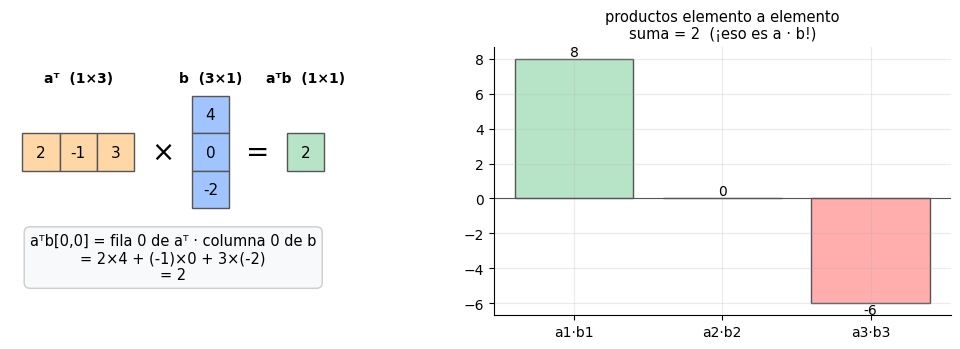

In [ ]:
show_dot_product([2, -1, 3], [4, 0, -2])

> 🔗 **Conexión con el notebook.** La predicción del modelo para **una sola casa** es exactamente un producto punto:
> $$\hat y = \mathbf w\cdot\mathbf x + b$$
> cada *peso* $w_j$ multiplica su *feature* $x_j$ y todo se suma. Mira el mismo dibujo con una casa de 120 m², 3 cuartos, 10 años de antigüedad y a 5 km del centro (pesos inventados):

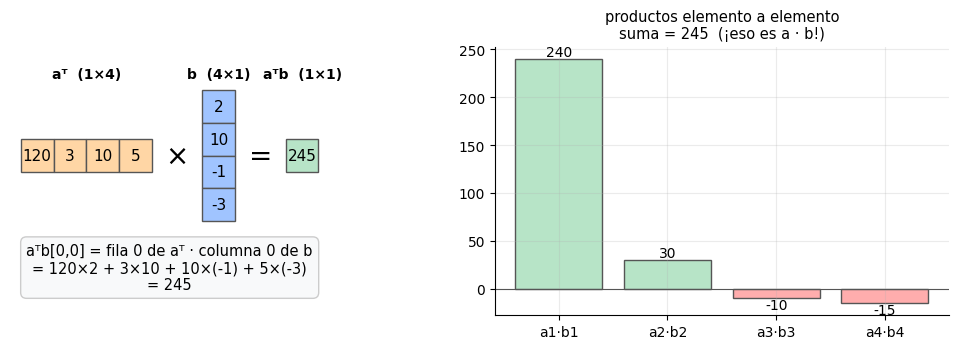

In [ ]:
house = [120, 3, 10, 5]          # size (m²), bedrooms, age (years), distance (km)
weights = [2.0, 10.0, -1.0, -3.0]  # made-up weights
show_dot_product(house, weights)

### ✍️ Mini-ejercicio 1.1

Calcula el producto punto de `a` y `b` de dos maneras:

- **(a)** con un ciclo `for` que acumula los productos `a[k] * b[k]`;
- **(b)** con NumPy, en **una sola línea**.

<details>
<summary>💡 Hint 1 (idea)</summary>

Para (a) necesitas una variable acumuladora que empiece en 0 y a la que le sumes `a[k] * b[k]` en cada vuelta del ciclo.
</details>

<details>
<summary>💡 Hint 2 (NumPy)</summary>

Para (b) NumPy tiene el operador `@` (y la función `np.dot`) que hace justo lo que describe la fórmula.
</details>

In [ ]:
a = np.array([2, -1, 3])
b = np.array([4, 0, -2])

# (a) with a for loop
dot_loop = 0
for k in range(len(a)):
    dot_loop += a[k] * b[k]

# (b) with NumPy, one line
dot_numpy = a @ b  # (3,) @ (3,) -> escalar

print("loop :", dot_loop)
print("numpy:", dot_numpy)

loop : 2
numpy: 2


In [ ]:
# ✅ Test (no modificar)
assert dot_numpy is not None, "Todavía no calculas dot_numpy: escribe tu código en la celda anterior."
assert dot_loop == 2, f"El resultado con ciclo debería ser 2 y obtuviste {dot_loop}. ¿Acumulaste con +=?"
assert dot_numpy == 2, f"El resultado con NumPy debería ser 2 y obtuviste {dot_numpy}."
assert dot_loop == dot_numpy, "Ambos métodos deben dar el mismo número."
mark_passed("Mini-ejercicio 1.1: producto punto")

✅ ¡Mini-ejercicio 1.1: producto punto: correcto!


## 1.2 Matriz × vector

Una matriz $X$ de tamaño $(m\times n)$ multiplicada por un vector $\mathbf w$ de tamaño $n$ da un vector de tamaño $m$. **Cada elemento del resultado es el producto punto de una fila de $X$ con $\mathbf w$**:

$$(X\mathbf w)_i \;=\; \mathbf x^{(i)}\cdot\mathbf w \;=\; \sum_{j=1}^{n} X_{ij}\,w_j$$

Es decir, una matriz × vector son **$m$ productos punto hechos a la vez**.

📐 Regla de shapes: $(m\times n)\cdot(n)\;\rightarrow\;(m)$. Las dimensiones **internas** ($n$ y $n$) deben coincidir.

Imagina **3 casas** y **2 features** (m², cuartos). Cada **fila** de $X$ es una casa:

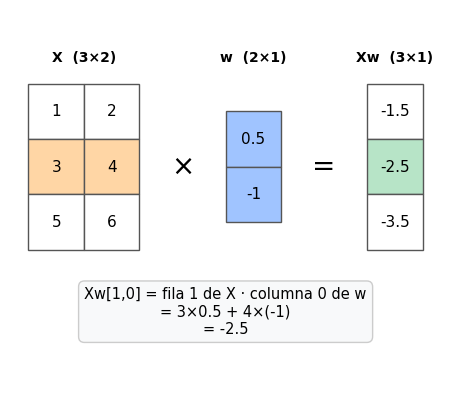

array([[-1.5],
       [-2.5],
       [-3.5]])

In [ ]:
X_small = np.array([[1, 2],
                    [3, 4],
                    [5, 6]])       # 3 examples, 2 features  -> shape (3, 2)
w_small = np.array([0.5, -1.0])    # one weight per feature  -> shape (2,)

show_matmul(X_small, w_small, i=1, j=0, names=("X", "w", "Xw"))

> 🔗 **Conexión con el notebook.** Con una sola multiplicación `X @ w` obtenemos las predicciones de **todas** las casas, sin ciclos:
> $$\hat{\mathbf y} \;=\; X\mathbf w + b$$
> El escalar $b$ se suma a **cada** elemento del vector (NumPy lo llama *broadcasting*). Esto es literalmente lo que escribirás en el Ejercicio 1.

Otra forma de verlo: $X\mathbf w$ es una **combinación lineal de las columnas** de $X$ (cada columna = una feature, pesada por su $w_j$):

In [ ]:
by_rows = X_small @ w_small
by_columns = w_small[0] * X_small[:, 0] + w_small[1] * X_small[:, 1]
print("X @ w                  :", by_rows)
print("w1*col1 + w2*col2      :", by_columns)
print("¿son iguales?          :", np.allclose(by_rows, by_columns))

X @ w                  : [-1.5 -2.5 -3.5]
w1*col1 + w2*col2      : [-1.5 -2.5 -3.5]
¿son iguales?          : True


### ✍️ Mini-ejercicio 1.2

Calcula las predicciones `y_hat` de las 3 casas usando `X_small`, `w_small` y un sesgo `b_small = 10`. **Sin ciclos.**

<details>
<summary>💡 Hint 1 (idea)</summary>

El modelo es $\hat{\mathbf y} = X\mathbf w + b$. Primero la multiplicación matriz × vector, luego sumas $b$.
</details>

<details>
<summary>💡 Hint 2 (shapes)</summary>

`X_small` es `(3, 2)` y `w_small` es `(2,)`. Las dimensiones internas (2 y 2) coinciden, así que el resultado tiene shape `(3,)`.
</details>

In [ ]:
b_small = 10.0

y_hat_small = X_small @ w_small + b_small  # (3, 2) @ (2,) -> (3,)

print("y_hat_small =", y_hat_small)

y_hat_small = [8.5 7.5 6.5]


In [ ]:
# ✅ Test (no modificar)
assert y_hat_small is not None, "Todavía no calculas y_hat_small."
assert y_hat_small.shape == (3,), f"Shape incorrecto: esperaba (3,) y obtuve {y_hat_small.shape}."
assert np.allclose(y_hat_small, [8.5, 7.5, 6.5]), f"Valores incorrectos: {y_hat_small}. Esperaba [8.5, 7.5, 6.5]."
mark_passed("Mini-ejercicio 1.2: matriz × vector")

✅ ¡Mini-ejercicio 1.2: matriz × vector: correcto!


## 1.3 Matriz × matriz

Si $A$ es $(m\times n)$ y $B$ es $(n\times p)$, el producto $C=AB$ es $(m\times p)$ y

$$C_{ij} \;=\; (\text{fila } i \text{ de } A)\cdot(\text{columna } j \text{ de } B) \;=\; \sum_{k=1}^{n} A_{ik}\,B_{kj}$$

O sea: **cada celda de $C$ es un producto punto** (fila de $A$ con columna de $B$). Cambia `i` y `j` para ver cómo se calcula cada celda:

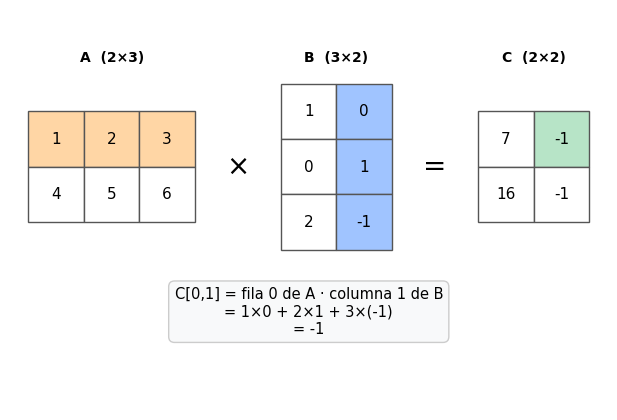

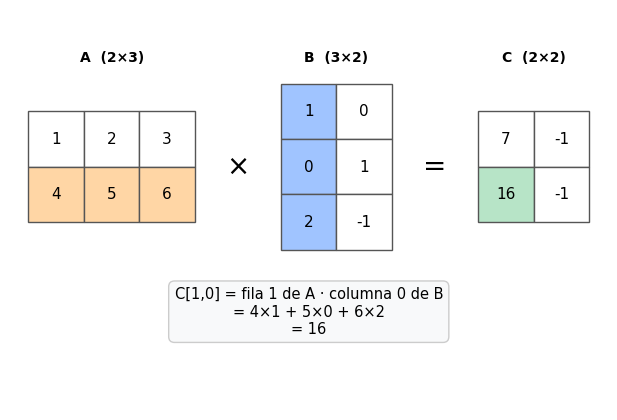

array([[ 7., -1.],
       [16., -1.]])

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])        # (2, 3)
B = np.array([[1,  0],
              [0,  1],
              [2, -1]])          # (3, 2)

show_matmul(A, B, i=0, j=1)
show_matmul(A, B, i=1, j=0)

⚠️ **Dos reglas que debes recordar**

1. **Las dimensiones internas deben coincidir:** $(m\times \mathbf n)\cdot(\mathbf n\times p)\rightarrow(m\times p)$.
2. **El orden importa:** en general $AB \neq BA$ (¡incluso pueden tener shapes distintos!).

In [ ]:
print("A @ B  tiene shape:", (A @ B).shape)
print("B @ A  tiene shape:", (B @ A).shape, "  <- ¡distinto!")

# What does a shape error look like? (so you recognize it when it happens to you)
try:
    A @ A
except ValueError as err:
    print("\nA @ A falla porque (2,3) @ (2,3) no tiene dimensiones internas iguales:")
    print("   ValueError:", str(err)[:90], "...")

A @ B  tiene shape: (2, 2)
B @ A  tiene shape: (3, 3)   <- ¡distinto!

A @ A falla porque (2,3) @ (2,3) no tiene dimensiones internas iguales:
   ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?, ...


> 🔗 **Conexión con el notebook.** Aquí aparece la **transpuesta** $X^\top$, que "voltea" la matriz (filas ↔ columnas). Si $X$ es $(m\times n)$ entonces $X^\top$ es $(n\times m)$. Y mira lo que pasa al multiplicar $X^\top$ por el vector de errores $\mathbf e=\hat{\mathbf y}-\mathbf y$:
> $$X^\top \mathbf e \;:\quad (n\times m)\cdot(m)\;\rightarrow\;(n)$$
> El resultado tiene **un número por cada feature**: ¡esa es la forma del gradiente $\nabla_{\mathbf w}J$! Cada entrada $j$ es el producto punto de la **columna $j$ de $X$** (la feature $j$ de todas las casas) con el vector de errores. Lo verás completo en la sección 3.
>
> Además: (1) $X^\top X$ aparece en la *ecuación normal*, la solución exacta de la regresión lineal que usaremos solo para **verificar** tus resultados; y (2) en Deep Learning, una capa densa es $X W$ con $W$ de tamaño $(n\times h)$: **¡$h$ regresiones lineales a la vez!**

Veámoslo con las 3 casas de antes y un vector de errores inventado:

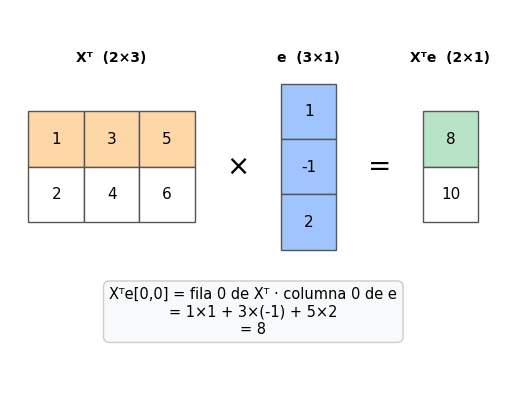

array([[ 8.],
       [10.]])

In [ ]:
e_small = np.array([1.0, -1.0, 2.0])   # made-up errors (y_hat - y) for the 3 houses

show_matmul(X_small.T, e_small, i=0, j=0, names=("Xᵀ", "e", "Xᵀe"))

### ✍️ Mini-ejercicio 1.3

Calcula:

- **(a)** `C = A @ B` (con las matrices `A` y `B` de arriba).
- **(b)** `grad_numerator = X_small.T @ e_small` (la transpuesta de `X_small` por el vector de errores).

<details>
<summary>💡 Hint 1</summary>

NumPy usa el mismo operador `@` para producto punto, matriz × vector y matriz × matriz. Él decide según los shapes.
</details>

<details>
<summary>💡 Hint 2</summary>

La transpuesta se obtiene con el atributo `.T` (por ejemplo `X_small.T`).
</details>

In [ ]:
C = A @ B  # (2, 3) @ (3, 2) -> (2, 2)
grad_numerator = X_small.T @ e_small  # (2, 3) @ (3,) -> (2,)

print("C =\n", C)
print("grad_numerator =", grad_numerator)

C =
 [[ 7 -1]
 [16 -1]]
grad_numerator = [ 8. 10.]


In [ ]:
# ✅ Test (no modificar)
assert C is not None and grad_numerator is not None, "Todavía no calculas C y grad_numerator."
assert C.shape == (2, 2), f"C debería ser (2, 2) y es {C.shape}."
assert np.allclose(C, [[7, -1], [16, -1]]), f"C incorrecta:\n{C}"
assert grad_numerator.shape == (2,), f"grad_numerator debería tener shape (2,) y tiene {grad_numerator.shape}."
assert np.allclose(grad_numerator, [8, 10]), f"grad_numerator incorrecto: {grad_numerator}. Esperaba [8, 10]."
mark_passed("Mini-ejercicio 1.3: matriz × matriz")

✅ ¡Mini-ejercicio 1.3: matriz × matriz: correcto!


## 1.4 Hoja de trucos: shapes que usarás en este notebook

Con $m$ ejemplos y $n$ features:

| Expresión | Entradas | Salida | ¿Qué significa? |
|---|---|---|---|
| `X @ w` | $(m,n)\cdot(n,)$ | $(m,)$ | predicción de **todos** los ejemplos |
| `e @ e` | $(m,)\cdot(m,)$ | escalar | suma de errores al cuadrado (producto punto de $\mathbf e$ consigo mismo) |
| `X.T @ e` | $(n,m)\cdot(m,)$ | $(n,)$ | una cifra **por feature** → el gradiente |
| `X.T @ X` | $(n,m)\cdot(m,n)$ | $(n,n)$ | relación entre features (ecuación normal) |

💡 **Truco de depuración:** cuando algo falle, imprime `.shape` de cada variable y verifica las dimensiones internas.

---
# 2️⃣ El problema: predecir el precio de una casa

Tenemos datos (sintéticos pero realistas) de **400 casas**. Para cada una conocemos 4 *features*:

| Feature | Descripción |
|---|---|
| `size_m2` | tamaño en metros cuadrados |
| `bedrooms` | número de cuartos |
| `age_years` | antigüedad en años |
| `distance_km` | distancia al centro de la ciudad (km) |

y queremos predecir `price`: el precio **en miles de dólares**. Es un problema de **regresión lineal multivariable** (varias features → un número).

La celda siguiente genera los datos y los separa en **entrenamiento (80 %)** y **validación (20 %)**:

- con el conjunto de **entrenamiento** el algoritmo aprende los parámetros;
- con el de **validación** (que *nunca* ve durante el aprendizaje) medimos qué tan bien generaliza.

*(No necesitas entender cómo se generan los datos; es un helper.)*

In [ ]:
def make_housing_data(m=400, seed=SEED):
    """Synthetic housing data. Returns X (m, 4) and y (m,) with prices in thousands of USD."""
    rng = np.random.default_rng(seed)
    size = rng.uniform(40, 250, m)
    bedrooms = np.clip(np.round(size / 55 + rng.normal(0, 0.7, m)), 1, 6)
    age = rng.uniform(0, 60, m)
    dist = rng.uniform(0.5, 25, m)
    price = (40 + 1.5 * size + 0.006 * size ** 2 + 8 * bedrooms - 1.0 * age
             - 4.0 * dist + 0.08 * dist ** 2 + rng.normal(0, 15, m))
    return np.column_stack([size, bedrooms, age, dist]), price


feature_names = ["size_m2", "bedrooms", "age_years", "distance_km"]
X_all, y_all = make_housing_data()

# 80 % train / 20 % validation (shuffled with a fixed seed)
perm = np.random.default_rng(0).permutation(len(y_all))
n_train = int(0.8 * len(y_all))
X_train, y_train = X_all[perm[:n_train]], y_all[perm[:n_train]]
X_val, y_val = X_all[perm[n_train:]], y_all[perm[n_train:]]

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}    y_val  : {y_val.shape}\n")
print("Primeras 5 casas de entrenamiento:")
print("  " + "  ".join(f"{n:>12}" for n in feature_names) + "  " + f"{'price (k$)':>12}")
for row, price in zip(X_train[:5], y_train[:5]):
    print("  " + "  ".join(f"{v:>12.1f}" for v in row) + "  " + f"{price:>12.1f}")

X_train: (320, 4)   y_train: (320,)
X_val  : (80, 4)    y_val  : (80,)

Primeras 5 casas de entrenamiento:
       size_m2      bedrooms     age_years   distance_km    price (k$)
         112.8           3.0          20.4           3.4         274.2
         145.2           3.0           2.4          22.5         339.4
          60.8           1.0          11.6          18.8         106.5
          73.9           2.0          57.6          20.8         111.3
         204.0           4.0           1.4           9.8         582.1


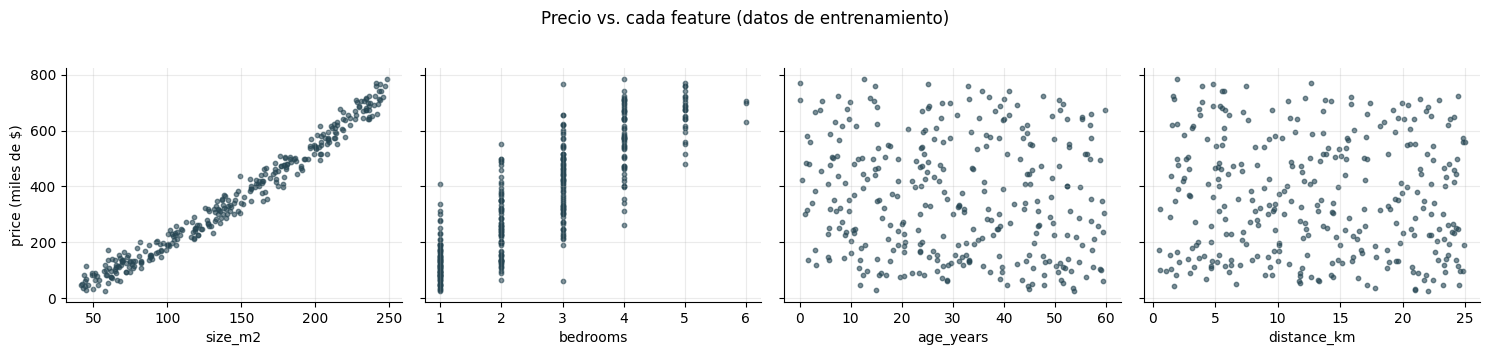

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for j, ax in enumerate(axes):
    ax.scatter(X_train[:, j], y_train, s=10, alpha=0.6, color="#264653")
    ax.set_xlabel(feature_names[j])
axes[0].set_ylabel("price (miles de $)")
plt.suptitle("Precio vs. cada feature (datos de entrenamiento)", y=1.03)
plt.tight_layout()
plt.show()

👀 **Observa:** el precio crece con el tamaño, baja con la antigüedad y la distancia... y fíjate en las **escalas**: `size_m2` va de 40 a 250 mientras que `bedrooms` va de 1 a 6. Esto será muy importante en la sección 6. También nota que la relación precio–tamaño parece ligeramente **curva**: guárdalo para la sección 7.

### 📏 Notación

| Símbolo | Significado | Shape |
|:-:|---|:-:|
| $m$ | número de ejemplos (casas) | escalar |
| $n$ | número de features | escalar |
| $X$ | matriz de features (una **fila** por casa) | $(m, n)$ |
| $\mathbf x^{(i)}$ | features de la casa $i$ (fila $i$ de $X$) | $(n,)$ |
| $\mathbf y$ | precios reales | $(m,)$ |
| $\mathbf w$ | pesos (uno por feature) | $(n,)$ |
| $b$ | sesgo (*bias*) | escalar |
| $\hat{\mathbf y}$ | predicciones | $(m,)$ |
| $\mathbf e$ | errores $=\hat{\mathbf y}-\mathbf y$ | $(m,)$ |
| $\alpha$ | learning rate | escalar |

---
# 3️⃣ Teoría: las cuatro fórmulas que necesitas

Todas las fórmulas que vas a programar están aquí. **No tienes que deducirlas**, solo traducirlas a código.

## 3.1 Modelo

Para **un** ejemplo $i$ (producto punto, sección 1.1) y para **todos** a la vez (matriz × vector, sección 1.2):

$$\hat y^{(i)} = \mathbf w\cdot\mathbf x^{(i)} + b = \sum_{j=1}^{n} w_j\,x^{(i)}_j + b
\qquad\Longrightarrow\qquad
\boxed{\;\hat{\mathbf y} = X\mathbf w + b\;}$$

## 3.2 Función de costo (error cuadrático medio)

Mide qué tan mal predice el modelo. Con el vector de errores $\mathbf e=\hat{\mathbf y}-\mathbf y$:

$$J(\mathbf w,b)=\frac{1}{2m}\sum_{i=1}^{m}\Big(\hat y^{(i)}-y^{(i)}\Big)^2
\qquad\Longrightarrow\qquad
\boxed{\;J(\mathbf w,b)=\frac{1}{2m}\,\mathbf e^\top\mathbf e\;}$$

(El $\tfrac12$ solo sirve para que el 2 de la derivada se cancele después). Fíjate: $\mathbf e^\top\mathbf e$ es el **producto punto de $\mathbf e$ consigo mismo** = suma de cuadrados.

## 3.3 Gradiente

El gradiente apunta hacia donde el costo **sube más rápido**; por eso caminaremos en sentido contrario.

$$\frac{\partial J}{\partial w_j}=\frac1m\sum_{i=1}^{m}\Big(\hat y^{(i)}-y^{(i)}\Big)\,x^{(i)}_j
\qquad\qquad
\frac{\partial J}{\partial b}=\frac1m\sum_{i=1}^{m}\Big(\hat y^{(i)}-y^{(i)}\Big)$$

**Versión vectorizada** (¡la que viste en la sección 1.3!):

$$\boxed{\;\nabla_{\mathbf w}J=\frac1m\,X^\top\mathbf e\;}\qquad\qquad
\boxed{\;\frac{\partial J}{\partial b}=\frac1m\sum_{i=1}^{m}e_i\;}$$

<details>
<summary>🔎 ¿De dónde sale? (opcional)</summary>

Por la regla de la cadena, $\dfrac{\partial}{\partial w_j}\dfrac{1}{2m}\sum_i e_i^2=\dfrac{1}{2m}\sum_i 2\,e_i\,\dfrac{\partial e_i}{\partial w_j}$ y como $e_i=\mathbf w\cdot\mathbf x^{(i)}+b-y^{(i)}$, se cumple $\dfrac{\partial e_i}{\partial w_j}=x^{(i)}_j$. El 2 cancela al $\tfrac12$ y queda la fórmula de arriba. Para $b$ la derivada de $e_i$ es 1.
</details>

## 3.4 Regla de actualización

En cada iteración damos un paso **contra** el gradiente, de tamaño proporcional al *learning rate* $\alpha$:

$$\boxed{\;\mathbf w\leftarrow\mathbf w-\alpha\,\nabla_{\mathbf w}J\qquad\qquad b\leftarrow b-\alpha\,\frac{\partial J}{\partial b}\;}$$

⚠️ La actualización es **simultánea**: primero calculas *ambos* gradientes con los parámetros actuales y *después* actualizas $\mathbf w$ y $b$.

## 3.5 El algoritmo completo

```
inicializar  w = 0  (vector de ceros),  b = 0
repetir num_iters veces:
    1. calcular el gradiente (dj_dw, dj_db) con los parámetros actuales
    2. actualizar w y b con la regla de la sección 3.4
    3. guardar el nuevo costo J(w, b) en un historial
```

## 3.6 Intuición del *learning rate* $\alpha$

Para ver el efecto de $\alpha$ sin distracciones usamos una **parábola de una sola variable**, $J(w)=(w-3)^2$, y damos 8 pasos de gradient descent empezando en $w=-2$ con tres valores de $\alpha$:

In [ ]:
def plot_learning_rate_intuition(alphas=(0.05, 0.4, 1.05), w_start=-2.0, w_target=3.0, steps=8):
    """1D toy example J(w) = (w - 3)^2 to see what the learning rate does."""
    titles = ["α muy pequeño", "α bien elegido", "α muy grande"]
    fig, axes = plt.subplots(1, len(alphas), figsize=(14, 3.8), sharey=True)
    grid = np.linspace(-4.5, 8.5, 200)
    for ax, alpha, title in zip(axes, alphas, titles):
        ax.plot(grid, (grid - w_target) ** 2, color="#555555", lw=1.5)
        w = w_start
        path = [w]
        for _ in range(steps):
            w = w - alpha * 2 * (w - w_target)   # dJ/dw = 2 (w - 3)
            path.append(w)
        path = np.array(path)
        ax.plot(path, (path - w_target) ** 2, "o-", color="#e76f51", ms=5, lw=1)
        ax.plot(path[0], (path[0] - w_target) ** 2, "o", color="#2a9d8f", ms=9, label="inicio")
        ax.set_title(f"{title}\nα = {alpha}", fontsize=11)
        ax.set_xlabel("w")
        ax.set_xlim(-4.5, 8.5)
        ax.set_ylim(-3, 90)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("J(w)")
    axes[0].legend(loc="upper center")
    plt.tight_layout()
    plt.show()

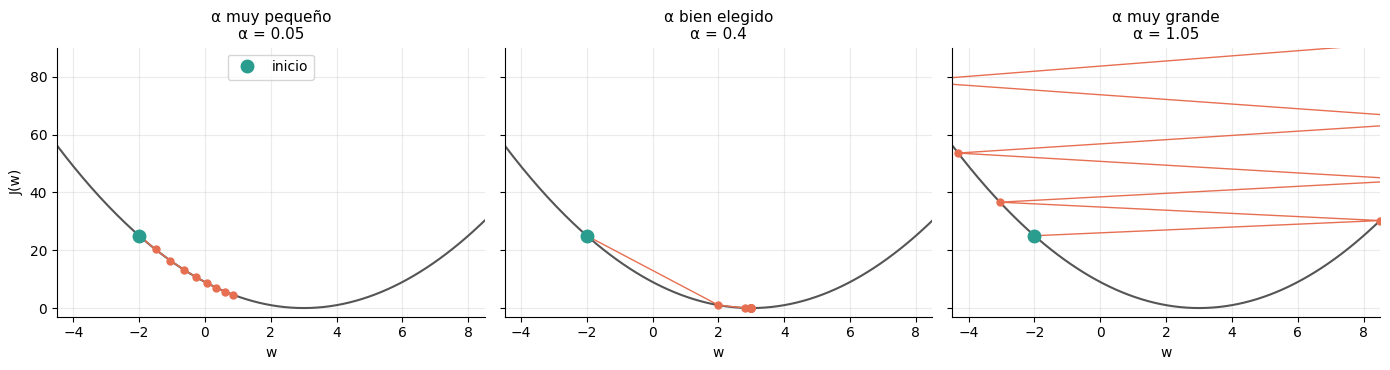

In [ ]:
plot_learning_rate_intuition()

- **α muy pequeño** → el costo baja, pero tan despacio que necesitarías miles de iteraciones.
- **α bien elegido** → llega al mínimo rápido.
- **α muy grande** → cada paso se pasa del mínimo y cae **más arriba** en el otro lado: el costo **aumenta** en cada paso y el algoritmo **diverge**.

Esto mismo lo vas a reproducir con los datos de casas en los experimentos 2, 3 y 4. 🚀

---
# 4️⃣ 📘 Solución de referencia SIN vectorizar

Antes de vectorizar resolvamos el problema **como lo harías "a mano"**, traduciendo literalmente las fórmulas con $\sum$ a ciclos `for`. Esta implementación está **completa y es correcta**. Tiene dos usos:

1. **Entender** el algoritmo paso a paso.
2. **Servir como oráculo:** tu versión vectorizada debe dar *exactamente los mismos números* (los tests de la sección 5 las comparan).

Lee el código con calma. Observa qué partes se repiten y qué operación de álgebra lineal (sección 1) hay detrás de cada bloque:

| Bloque con ciclos | ¿Qué operación de la sección 1 es? |
|---|---|
| doble `for` (ejemplos × features) acumulando `X[i, j] * w[j]` | ? |
| `for` acumulando `error ** 2` | ? |
| doble `for` acumulando `error * X[i, j]` en `dj_dw[j]` | ? |
| `for j` actualizando `w[j] = w[j] - alpha * dj_dw[j]` | operación elemento a elemento |

🤔 Intenta responder los "?" antes de seguir: esas respuestas son tu plan para la sección 5.

In [ ]:
# ======================= REFERENCE IMPLEMENTATION WITH LOOPS (do not modify) =======================

def predict_loop(X, w, b):
    """y_hat[i] = sum_j X[i, j] * w[j] + b, computed with explicit loops."""
    m, n = X.shape
    y_hat = np.zeros(m)
    for i in range(m):
        for j in range(n):
            y_hat[i] += X[i, j] * w[j]
        y_hat[i] += b
    return y_hat


def compute_cost_loop(X, y, w, b):
    """J(w, b) = 1/(2m) * sum_i (y_hat_i - y_i)^2"""
    m, n = X.shape
    total = 0.0
    for i in range(m):
        y_hat_i = b
        for j in range(n):
            y_hat_i += X[i, j] * w[j]
        total += (y_hat_i - y[i]) ** 2
    return total / (2 * m)


def compute_gradient_loop(X, y, w, b):
    """dJ/dw_j = 1/m * sum_i e_i * X[i, j]     dJ/db = 1/m * sum_i e_i"""
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.0
    for i in range(m):
        y_hat_i = b
        for j in range(n):
            y_hat_i += X[i, j] * w[j]
        error = y_hat_i - y[i]
        for j in range(n):
            dj_dw[j] += error * X[i, j]
        dj_db += error
    return dj_dw / m, dj_db / m


def gradient_descent_loop(X, y, w_init, b_init, alpha, num_iters):
    """Gradient descent with loops. J_history and w_history have num_iters + 1 entries
    (entry 0 = initial parameters, entry k = parameters after k updates)."""
    w = np.array(w_init, dtype=float)      # copy: never modify the caller's array
    b = float(b_init)
    J_history = [compute_cost_loop(X, y, w, b)]
    w_history = [w.copy()]
    for _ in range(num_iters):
        dj_dw, dj_db = compute_gradient_loop(X, y, w, b)   # 1. gradient with CURRENT parameters
        for j in range(len(w)):                            # 2. simultaneous update
            w[j] = w[j] - alpha * dj_dw[j]
        b = b - alpha * dj_db
        J_history.append(compute_cost_loop(X, y, w, b))    # 3. record the cost
        w_history.append(w.copy())
    return w, b, J_history, w_history

## 4.1 Probémosla en un problema pequeño

Para tener algo rápido y fácil de verificar usamos un **dataset de juguete**: 60 ejemplos, 3 features ya "bien escaladas", y una relación conocida

$$y = 3x_1 - 2x_2 + 0.5x_3 + 4 + \text{ruido}$$

Si gradient descent funciona, debería **recuperar** $\mathbf w\approx(3,-2,0.5)$ y $b\approx4$.

Costo inicial : 14.0000
Costo final   : 0.0399   (tras 100 iteraciones)
w aprendido   : [ 3.104  -1.9876  0.5193]     (real: [ 3.  -2.   0.5])
b aprendido   : 3.9990   (real: 4.0)
Tiempo (ciclos): 0.064 s


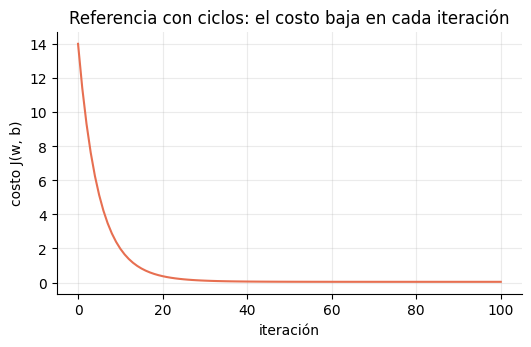

In [ ]:
rng = np.random.default_rng(SEED)
m_toy, n_toy = 60, 3
X_toy = rng.normal(size=(m_toy, n_toy))
w_true_toy, b_true_toy = np.array([3.0, -2.0, 0.5]), 4.0
y_toy = X_toy @ w_true_toy + b_true_toy + rng.normal(scale=0.3, size=m_toy)

t0 = time.perf_counter()
w_ref, b_ref, J_ref, w_hist_ref = gradient_descent_loop(X_toy, y_toy, np.zeros(n_toy), 0.0, alpha=0.1, num_iters=100)
t_loop = time.perf_counter() - t0

print(f"Costo inicial : {J_ref[0]:.4f}")
print(f"Costo final   : {J_ref[-1]:.4f}   (tras {len(J_ref) - 1} iteraciones)")
print(f"w aprendido   : {w_ref}     (real: {w_true_toy})")
print(f"b aprendido   : {b_ref:.4f}   (real: {b_true_toy})")
print(f"Tiempo (ciclos): {t_loop:.3f} s")

plt.figure(figsize=(6, 3.4))
plt.plot(J_ref, color="#e76f51")
plt.xlabel("iteración")
plt.ylabel("costo J(w, b)")
plt.title("Referencia con ciclos: el costo baja en cada iteración")
plt.show()

✅ El costo baja en cada iteración y los parámetros se acercan a los reales. Guardamos `w_ref`, `b_ref`, `J_ref` y `w_hist_ref`: serán tu **referencia** en los tests.

## 4.2 Una segunda referencia: la solución exacta (ecuación normal)

La regresión lineal tiene además una solución **cerrada** (sin iterar). Agregando una columna de unos a $X$ para absorber el sesgo, $A=[X\;|\;\mathbf 1]$, los mejores parámetros $\boldsymbol\theta=(\mathbf w,b)$ cumplen la *ecuación normal*:

$$A^\top A\,\boldsymbol\theta = A^\top\mathbf y$$

(¡aquí aparece el producto matriz × matriz $A^\top A$ de la sección 1.3!). NumPy la resuelve con `np.linalg.lstsq`. **La usaremos solo para verificar** que gradient descent converge al mismo óptimo: no es parte de lo que debes implementar.

In [ ]:
def closed_form_solution(X, y):
    """Exact least-squares solution (normal equation) via NumPy. Used ONLY as a reference."""
    A = np.hstack([X, np.ones((X.shape[0], 1))])        # append a column of ones for the bias
    theta, *_ = np.linalg.lstsq(A, y, rcond=None)
    return theta[:-1], theta[-1]


w_exact, b_exact = closed_form_solution(X_toy, y_toy)
print("Solución exacta   w =", w_exact, "  b = %.4f" % b_exact)
print("Gradient descent  w =", w_ref, "  b = %.4f" % b_ref)

Solución exacta   w = [ 3.1058 -1.9918  0.5268]   b = 3.9986
Gradient descent  w = [ 3.104  -1.9876  0.5193]   b = 3.9990


---
# 5️⃣ ✍️ Tu implementación vectorizada

Ahora te toca a ti. Vas a reescribir las cuatro funciones de la sección 4 **sin ningún ciclo `for` sobre los ejemplos o las features** (solo el ciclo de iteraciones de gradient descent, que sí es inevitable).

Cada ejercicio tiene:
1. la **fórmula** y los **shapes**,
2. el **esqueleto** de la función (solo debes llenar donde dice `# tu código aquí`),
3. **hints** desplegables,
4. un **test** que compara tu función contra la versión con ciclos de la sección 4.

Los tests también miden la **velocidad**: si usas ciclos `for`, el test de vectorización te lo dirá. 😉

---
## Ejercicio 1 — `predict`

🎯 **Objetivo:** calcular las predicciones de **todos** los ejemplos de una sola vez.

$$\hat{\mathbf y}=X\mathbf w+b$$

📐 **Shapes:** `X` → $(m,n)$ · `w` → $(n,)$ · `b` → escalar · **salida** `y_hat` → $(m,)$

<details>
<summary>💡 Hint 1 (idea)</summary>

Es exactamente la sección 1.2: matriz × vector, y después el sesgo.
</details>

<details>
<summary>💡 Hint 2 (NumPy)</summary>

Usa el operador `@` para multiplicar `X` y `w`. El escalar `b` se suma a todo el vector automáticamente (*broadcasting*).
</details>

<details>
<summary>💡 Hint 3 (casi la respuesta)</summary>

`y_hat = ____ @ ____ + ____`
</details>

In [ ]:
def predict(X, w, b):
    """Linear model predictions for all examples at once.

    Args:
        X: (m, n) feature matrix
        w: (n,) weights
        b: float, bias
    Returns:
        y_hat: (m,) predictions
    """
    y_hat = X @ w + b  # (m, n) @ (n,) + escalar -> (m,)
    return y_hat

In [ ]:
# ✅ Test (no modificar)
w_t, b_t = np.array([0.5, -1.0, 2.0]), 1.5
y_hat_t = predict(X_toy, w_t, b_t)

assert y_hat_t is not None, "predict devolvió None: ¿ya escribiste tu código en la celda anterior?"
assert isinstance(y_hat_t, np.ndarray), f"predict debe devolver un np.ndarray y devolvió {type(y_hat_t)}."
assert y_hat_t.shape == (m_toy,), f"Shape incorrecto: esperaba {(m_toy,)} y obtuve {y_hat_t.shape}. Recuerda: X (m,n) @ w (n,) -> (m,)."
assert np.allclose(y_hat_t, predict_loop(X_toy, w_t, b_t)), "Tus predicciones no coinciden con las de la versión con ciclos (predict_loop)."
assert predict(X_toy[:1], w_t, b_t).shape == (1,), "Debe funcionar también con un solo ejemplo (m = 1)."

# vectorization check: a huge input must be fast (a Python loop would take several seconds)
X_big, w_big = np.random.default_rng(1).normal(size=(200_000, 20)), np.ones(20)
t0 = time.perf_counter()
predict(X_big, w_big, 0.0)
elapsed = time.perf_counter() - t0
assert elapsed < 0.1, f"predict tardó {elapsed:.2f} s con 200 000 ejemplos: ¿estás usando ciclos for?"
mark_passed("Ejercicio 1: predict")

✅ ¡Ejercicio 1: predict: correcto!


---
## Ejercicio 2 — `compute_cost`

🎯 **Objetivo:** calcular el costo $J(\mathbf w,b)$ (un solo número) de forma vectorizada.

$$J(\mathbf w,b)=\frac{1}{2m}\,\mathbf e^\top\mathbf e\qquad\text{con}\qquad \mathbf e=\hat{\mathbf y}-\mathbf y$$

📐 **Shapes:** `error` → $(m,)$ · **salida** → escalar

<details>
<summary>💡 Hint 1 (idea)</summary>

Primero obtén las predicciones (¡ya tienes `predict`!) y resta `y` para tener el vector de errores. Luego eleva al cuadrado, suma y divide entre $2m$.
</details>

<details>
<summary>💡 Hint 2 (conexión con la sección 1.1)</summary>

"Elevar al cuadrado y sumar" es el **producto punto del vector de errores consigo mismo**: $\mathbf e^\top\mathbf e$. También puedes usar `np.sum(error ** 2)`; ambas formas son válidas.
</details>

<details>
<summary>💡 Hint 3 (casi la respuesta)</summary>

`error = predict(...) - y`
`cost = (algo con error) / (2 * m)`
</details>

In [ ]:
def compute_cost(X, y, w, b):
    """Mean squared error cost J(w, b) = 1/(2m) * sum((y_hat - y)^2).

    Args:
        X: (m, n) features, y: (m,) targets, w: (n,) weights, b: float bias
    Returns:
        cost: float
    """
    m = X.shape[0]
    error = predict(X, w, b) - y  # (m,)
    cost = (error @ error) / (2 * m)  # escalar
    return cost

In [ ]:
# ✅ Test (no modificar)
require("Ejercicio 1: predict")
J_t = compute_cost(X_toy, y_toy, w_t, b_t)

assert J_t is not None, "compute_cost devolvió None: ¿ya escribiste tu código?"
assert np.ndim(J_t) == 0, f"El costo debe ser UN número (escalar) y obtuviste un arreglo con shape {np.shape(J_t)}."
assert np.isclose(J_t, compute_cost_loop(X_toy, y_toy, w_t, b_t)), (
    f"Costo incorrecto: obtuviste {J_t:.6f} y la referencia con ciclos da {compute_cost_loop(X_toy, y_toy, w_t, b_t):.6f}. "
    "¿Dividiste entre 2m? ¿Elevaste el error al cuadrado?")
assert np.isclose(compute_cost(X_toy, y_toy, np.zeros(n_toy), 0.0), np.mean(y_toy ** 2) / 2), "Con w = 0 y b = 0 el costo debe ser mean(y²)/2."
w_opt_t, b_opt_t = closed_form_solution(X_toy, y_toy)
assert compute_cost(X_toy, y_toy, w_opt_t, b_opt_t) < J_t, "El costo en la solución exacta debe ser menor que en parámetros arbitrarios."

# vectorization check
y_big = X_big @ w_big
t0 = time.perf_counter()
compute_cost(X_big, y_big, w_big * 0.9, 0.0)
elapsed = time.perf_counter() - t0
assert elapsed < 0.1, f"compute_cost tardó {elapsed:.2f} s con 200 000 ejemplos: ¿estás usando ciclos for?"
mark_passed("Ejercicio 2: compute_cost")

✅ ¡Ejercicio 2: compute_cost: correcto!


---
## Ejercicio 3 — `compute_gradient`

🎯 **Objetivo:** calcular $\nabla_{\mathbf w}J$ y $\partial J/\partial b$ de forma vectorizada.

$$\nabla_{\mathbf w}J=\frac1m\,X^\top\mathbf e\qquad\qquad\frac{\partial J}{\partial b}=\frac1m\sum_{i=1}^{m}e_i$$

📐 **Shapes:** `X.T` → $(n,m)$ · `error` → $(m,)$ · `dj_dw` → $(n,)$ · `dj_db` → escalar

<details>
<summary>💡 Hint 1 (idea)</summary>

Necesitas el vector de errores, igual que en el Ejercicio 2.
</details>

<details>
<summary>💡 Hint 2 (conexión con la sección 1.3)</summary>

El gradiente respecto a $\mathbf w$ es una multiplicación **matriz transpuesta × vector**: $X^\top\mathbf e$ tiene shape $(n,)$, un valor por feature. Después divide entre $m$. El gradiente respecto a $b$ es simplemente el **promedio** de los errores.
</details>

<details>
<summary>💡 Hint 3 (casi la respuesta)</summary>

`error = predict(...) - y`
`dj_dw = (____.T @ ____) / m`
`dj_db = (algo con error) / m`
</details>

Antes de escribir tu código, una herramienta profesional: la **comprobación numérica del gradiente**. Aproxima la derivada con diferencias finitas, $\dfrac{J(w+\varepsilon)-J(w-\varepsilon)}{2\varepsilon}$, y la compara con tu fórmula. Si coinciden, tu gradiente casi seguro está bien. (Helper: no lo modifiques.)

In [ ]:
def numerical_gradient(cost_fn, X, y, w, b, eps=1e-6):
    """Approximate the gradient with central finite differences (helper for the tests)."""
    dj_dw = np.zeros(len(w))
    for j in range(len(w)):
        w_plus, w_minus = w.copy(), w.copy()
        w_plus[j] += eps
        w_minus[j] -= eps
        dj_dw[j] = (cost_fn(X, y, w_plus, b) - cost_fn(X, y, w_minus, b)) / (2 * eps)
    dj_db = (cost_fn(X, y, w, b + eps) - cost_fn(X, y, w, b - eps)) / (2 * eps)
    return dj_dw, dj_db

In [ ]:
def compute_gradient(X, y, w, b):
    """Gradient of the cost with respect to w and b.

    Args:
        X: (m, n) features, y: (m,) targets, w: (n,) weights, b: float bias
    Returns:
        dj_dw: (n,) gradient with respect to w
        dj_db: float, gradient with respect to b
    """
    m = X.shape[0]
    error = predict(X, w, b) - y  # (m,)
    dj_dw = (X.T @ error) / m  # (n, m) @ (m,) -> (n,)
    dj_db = np.mean(error)  # escalar
    return dj_dw, dj_db

In [ ]:
# ✅ Test (no modificar)
require("Ejercicio 1: predict", "Ejercicio 2: compute_cost")
dj_dw_t, dj_db_t = compute_gradient(X_toy, y_toy, w_t, b_t)

assert dj_dw_t is not None and dj_db_t is not None, "compute_gradient devolvió None: ¿ya escribiste tu código?"
assert isinstance(dj_dw_t, np.ndarray) and dj_dw_t.shape == (n_toy,), (
    f"dj_dw debe ser un arreglo con shape {(n_toy,)} (uno por feature) y obtuviste {np.shape(dj_dw_t)}.")
assert np.ndim(dj_db_t) == 0, f"dj_db debe ser UN número y obtuviste un arreglo con shape {np.shape(dj_db_t)}."

dw_ref, db_ref = compute_gradient_loop(X_toy, y_toy, w_t, b_t)
assert np.allclose(dj_dw_t, dw_ref), f"dj_dw no coincide con la referencia con ciclos.\n  tuyo      : {dj_dw_t}\n  referencia: {dw_ref}"
assert np.isclose(dj_db_t, db_ref), f"dj_db no coincide con la referencia: tuyo {dj_db_t:.6f}, referencia {db_ref:.6f}."

# numerical gradient check (uses YOUR compute_cost)
dw_num, db_num = numerical_gradient(compute_cost, X_toy, y_toy, w_t, b_t)
assert np.allclose(dj_dw_t, dw_num, atol=1e-5), "Tu dj_dw no coincide con el gradiente numérico."
assert np.isclose(dj_db_t, db_num, atol=1e-5), "Tu dj_db no coincide con el gradiente numérico."

# at the exact optimum the gradient must be (almost) zero
w_opt_t, b_opt_t = closed_form_solution(X_toy, y_toy)
dw_opt, db_opt = compute_gradient(X_toy, y_toy, w_opt_t, b_opt_t)
assert np.allclose(dw_opt, 0, atol=1e-8) and abs(db_opt) < 1e-8, "En el óptimo el gradiente debe ser ≈ 0."

# vectorization check
t0 = time.perf_counter()
compute_gradient(X_big, y_big, w_big * 0.9, 0.0)
elapsed = time.perf_counter() - t0
assert elapsed < 0.1, f"compute_gradient tardó {elapsed:.2f} s con 200 000 ejemplos: ¿estás usando ciclos for?"
mark_passed("Ejercicio 3: compute_gradient")

✅ ¡Ejercicio 3: compute_gradient: correcto!


---
## Ejercicio 4 — `gradient_descent`

🎯 **Objetivo:** juntar todo. En cada iteración: calcular el gradiente, actualizar $\mathbf w$ y $b$, y guardar el costo.

$$\mathbf w\leftarrow\mathbf w-\alpha\,\nabla_{\mathbf w}J\qquad\qquad b\leftarrow b-\alpha\,\frac{\partial J}{\partial b}$$

El esqueleto ya copia `w_init` (para no modificar el arreglo original) y ya guarda los historiales. **Tú solo escribes el cuerpo del ciclo**: el gradiente y la actualización.

📐 **Salidas:** `w` → $(n,)$ · `b` → escalar · `J_history` → lista de `num_iters + 1` costos · `w_history` → lista de `num_iters + 1` vectores $(n,)$

<details>
<summary>💡 Hint 1 (idea)</summary>

Mira el pseudocódigo de la sección 3.5 y la implementación `gradient_descent_loop` de la sección 4: la estructura es la misma, pero tus funciones vectorizadas hacen casi todo el trabajo.
</details>

<details>
<summary>💡 Hint 2 (orden)</summary>

Primero llama a `compute_gradient` con los parámetros **actuales**. Solo *después* actualizas `w` y `b`. (Si actualizaras `w` antes de calcular `dj_db`, usarías parámetros mezclados.)
</details>

<details>
<summary>💡 Hint 3 (casi la respuesta)</summary>

`dj_dw, dj_db = compute_gradient(...)`
`w = w - alpha * ____`
`b = b - alpha * ____`
</details>

In [ ]:
def gradient_descent(X, y, w_init, b_init, alpha, num_iters):
    """Batch gradient descent for multivariable linear regression.

    Args:
        X: (m, n) features, y: (m,) targets
        w_init: (n,) initial weights, b_init: float initial bias
        alpha: learning rate, num_iters: number of iterations
    Returns:
        w: (n,) final weights, b: float final bias
        J_history: list with num_iters + 1 costs (entry 0 = initial parameters)
        w_history: list with num_iters + 1 weight vectors
    """
    w = w_init.copy()                       # never modify the caller's array
    b = b_init
    J_history = [compute_cost(X, y, w, b)]
    w_history = [w.copy()]

    for i in range(num_iters):
        # Ambos gradientes usan los mismos parámetros actuales.
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        J_history.append(compute_cost(X, y, w, b))
        w_history.append(w.copy())

    return w, b, J_history, w_history

In [ ]:
# ✅ Test (no modificar)
require("Ejercicio 1: predict", "Ejercicio 2: compute_cost", "Ejercicio 3: compute_gradient")
w0 = np.zeros(n_toy)
w0_before = w0.copy()
w_s, b_s, J_s, wh_s = gradient_descent(X_toy, y_toy, w0, 0.0, 0.1, 100)

assert w_s is not None and b_s is not None, "gradient_descent devolvió None."
assert np.array_equal(w0, w0_before), "gradient_descent modificó w_init en el lugar. Usa `w = w - alpha * ...` (no `w -= ...`) o trabaja con la copia."
assert len(J_s) == 101, f"J_history debe tener num_iters + 1 = 101 entradas y tiene {len(J_s)}."
assert len(wh_s) == 101, f"w_history debe tener num_iters + 1 = 101 entradas y tiene {len(wh_s)}."
assert J_s[-1] < J_s[0], "El costo final no es menor que el inicial: ¿actualizaste w y b dentro del ciclo?"
assert all(J_s[k + 1] <= J_s[k] for k in range(100)), "Con α = 0.1 el costo debe bajar en TODAS las iteraciones."
assert np.allclose(J_s, J_ref), "Tu historial de costos no coincide con el de la referencia con ciclos (J_ref)."
assert np.allclose(w_s, w_ref) and np.isclose(b_s, b_ref), "Los parámetros finales no coinciden con los de la referencia con ciclos."
assert np.allclose(wh_s, w_hist_ref), "Tu historial de pesos no coincide con el de la referencia."

# a long run must reach the exact solution (normal equation)
w_long, b_long, J_long, _ = gradient_descent(X_toy, y_toy, np.zeros(n_toy), 0.0, 0.1, 1000)
w_ex, b_ex = closed_form_solution(X_toy, y_toy)
assert np.allclose(w_long, w_ex, atol=1e-3) and abs(b_long - b_ex) < 1e-3, "Con 1000 iteraciones deberías llegar a la solución exacta."
mark_passed("Ejercicio 4: gradient_descent")
print(f"   w aprendido = {w_long}   (solución exacta: {w_ex})")

✅ ¡Ejercicio 4: gradient_descent: correcto!
   w aprendido = [ 3.1058 -1.9918  0.5268]   (solución exacta: [ 3.1058 -1.9918  0.5268])


## 5.5 ⚡ ¿Cuánto ganaste al vectorizar?

Comparemos tu versión vectorizada con la de ciclos en un problema más grande (2 000 ejemplos, 10 features, 20 iteraciones). Ambas deben dar **el mismo resultado**; lo que cambia es el tiempo.

In [ ]:
require("Ejercicio 4: gradient_descent")
rng = np.random.default_rng(1)
X_speed = rng.normal(size=(2000, 10))
y_speed = X_speed @ rng.normal(size=10) + rng.normal(size=2000)

t0 = time.perf_counter()
w_a, b_a, _, _ = gradient_descent_loop(X_speed, y_speed, np.zeros(10), 0.0, 0.05, 20)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
w_b, b_b, _, _ = gradient_descent(X_speed, y_speed, np.zeros(10), 0.0, 0.05, 20)
t_vec = time.perf_counter() - t0

assert np.allclose(w_a, w_b) and np.isclose(b_a, b_b), "Los resultados deberían ser idénticos."
print(f"Con ciclos   : {t_loop:8.3f} s")
print(f"Vectorizado  : {t_vec:8.4f} s")
print(f"⚡ Speed-up   : ×{t_loop / t_vec:,.0f}")

Con ciclos   :    1.318 s
Vectorizado  :   0.0026 s
⚡ Speed-up   : ×511


---
# 6️⃣ ✍️ Normalización de features (z-score)

## 6.1 ¿Por qué?

Nuestras features tienen escalas muy distintas: `size_m2` está en las decenas/centenas, `bedrooms` en las unidades. Eso deforma la superficie del costo en un **valle largo y angosto**:

- en la dirección "empinada" necesitas un $\alpha$ **diminuto** para no divergir,
- pero con ese $\alpha$ diminuto avanzas **muy lento** en la dirección "plana".

Mira el mismo problema (con solo 2 features, `size_m2` y `distance_km`) **sin normalizar** y **normalizado**. Las curvas son las líneas de nivel del costo; la ★ es el óptimo.

In [ ]:
def plot_normalization_effect(X, y, f1=0, f2=3, names=("size", "distance"), num_iters=20, offset=2.0):
    """Cost contours + gradient descent path for two features, raw vs z-score normalized.

    Both features and y are centered so that b stays at 0 and the cost is a surface J(w1, w2).
    The start point is the same distance from the optimum measured in "standard deviations of the features".
    """
    Xs = X[:, [f1, f2]].astype(float)
    Xc = Xs - Xs.mean(axis=0)
    yc = y - y.mean()
    sigma = Xc.std(axis=0)
    Xz = Xc / sigma

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    settings = ((Xc, "Sin normalizar", 0.95, 1.0 / sigma), (Xz, "Normalizado (z-score)", 0.12, np.ones(2)))
    for ax, (data, title, frac, scale) in zip(axes, settings):
        m = data.shape[0]
        H = data.T @ data / m
        alpha = frac * 2 / np.linalg.eigvalsh(H).max()       # a fraction of the largest stable alpha
        w_star = np.linalg.lstsq(data, yc, rcond=None)[0]
        w = w_star + offset * scale                           # same "distance" to the optimum in both cases
        path = [w.copy()]
        for _ in range(num_iters):
            w = w - alpha * (data.T @ (data @ w - yc)) / m
            path.append(w.copy())
        path = np.array(path)
        span = np.abs(path - w_star).max(axis=0) * 1.25
        g1 = np.linspace(w_star[0] - span[0], w_star[0] + span[0], 150)
        g2 = np.linspace(w_star[1] - span[1], w_star[1] + span[1], 150)
        G1, G2 = np.meshgrid(g1, g2)
        E = data[:, [0]][:, :, None] * G1[None] + data[:, [1]][:, :, None] * G2[None] - yc[:, None, None]
        J = (E ** 2).sum(axis=0) / (2 * m)
        ax.contour(G1, G2, J, levels=np.geomspace(J.min() + 1, J.max(), 14), cmap="viridis", linewidths=1)
        ax.plot(path[:, 0], path[:, 1], "o-", color="#e76f51", ms=4, lw=1.2, label=f"GD ({num_iters} pasos)")
        ax.plot(*path[0], "o", color="#2a9d8f", ms=9, label="inicio")
        ax.plot(*w_star, "*", color="black", ms=14, label="óptimo")
        ax.set_title(f"{title}\nα = {alpha:.2g}", fontsize=12)
        ax.set_xlabel(f"w ({names[0]})")
        ax.set_ylabel(f"w ({names[1]})")
        ax.legend(loc="best", fontsize=9)
    plt.tight_layout()
    plt.show()

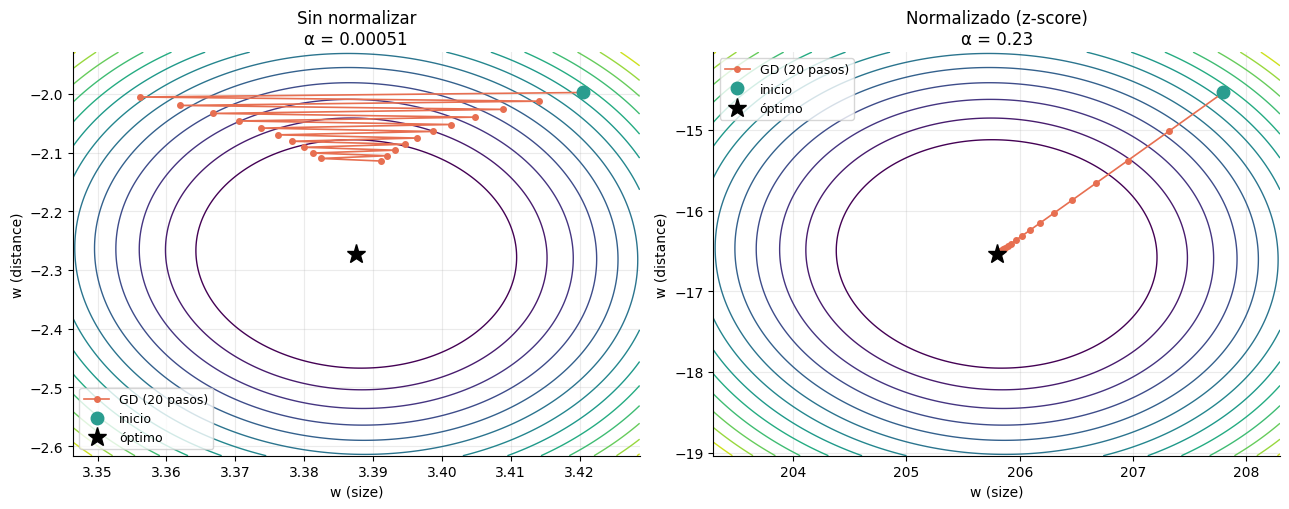

In [ ]:
plot_normalization_effect(X_train, y_train)

👀 **Sin normalizar**, el algoritmo rebota de lado a lado del valle (zigzag) y casi no avanza hacia el óptimo en 20 pasos. **Normalizado**, las líneas de nivel son casi círculos y el algoritmo va **directo** al mínimo.

## 6.2 La fórmula

Para cada feature (columna) $j$ calculamos su media y su desviación estándar **sobre los ejemplos** y la transformamos:

$$\mu_j=\frac1m\sum_{i=1}^m x^{(i)}_j\qquad\quad
\sigma_j=\sqrt{\frac1m\sum_{i=1}^m\big(x^{(i)}_j-\mu_j\big)^2}\qquad\quad
x'^{(i)}_j=\frac{x^{(i)}_j-\mu_j}{\sigma_j}$$

Después de normalizar, cada columna tiene **media 0 y desviación estándar 1**.

⚠️ **Regla de oro (evitar *data leakage*):** $\mu$ y $\sigma$ se calculan **solo con el conjunto de entrenamiento** y esos mismos valores se aplican a validación (y a cualquier dato nuevo). Por eso separamos el trabajo en dos funciones:

- `zscore_fit(X)` → calcula `mu` y `sigma` (una por columna);
- `zscore_transform(X, mu, sigma)` → aplica la fórmula.

## Ejercicio 5 — `zscore_fit` y `zscore_transform`

📐 **Shapes:** `X` → $(m,n)$ · `mu`, `sigma` → $(n,)$ · salida de `zscore_transform` → $(m,n)$

<details>
<summary>💡 Hint 1 (idea)</summary>

Necesitas **una media y una desviación por columna**, es decir, promediar "hacia abajo" a lo largo de los ejemplos.
</details>

<details>
<summary>💡 Hint 2 (NumPy)</summary>

`X.mean(axis=0)` y `X.std(axis=0)` operan a lo largo de las filas y devuelven un valor por columna. `axis=1` haría lo contrario (¡no es lo que queremos!).
</details>

<details>
<summary>💡 Hint 3 (broadcasting)</summary>

`X` es $(m,n)$ y `mu`, `sigma` son $(n,)$. NumPy "estira" automáticamente `mu` y `sigma` para operar con cada fila, así que no necesitas ciclos: `(X - ___) / ___`.
</details>

*(El caso de columnas constantes, con $\sigma=0$, ya está resuelto en el esqueleto para evitar dividir entre cero.)*

In [ ]:
def zscore_fit(X):
    """Per-feature mean and standard deviation (computed over the examples).

    Args:
        X: (m, n) features
    Returns:
        mu: (n,) means, sigma: (n,) standard deviations (1.0 where the column is constant)
    """
    mu = np.mean(X, axis=0)  # (n,), una media por columna
    sigma = np.std(X, axis=0)  # (n,), desviación poblacional
    sigma = np.where(sigma == 0, 1.0, sigma)   # given: avoids dividing by zero on constant columns
    return mu, sigma


def zscore_transform(X, mu, sigma):
    """Apply (X - mu) / sigma using statistics computed beforehand (e.g. on the training set).

    Args:
        X: (m, n) features, mu: (n,), sigma: (n,)
    Returns:
        X_norm: (m, n)
    """
    X_norm = (X - mu) / sigma  # broadcasting: (m, n) con (n,)
    return X_norm

In [ ]:
# ✅ Test (no modificar)
X_demo = np.array([[1.0, 200.0], [2.0, 220.0], [3.0, 240.0], [4.0, 260.0]])
mu_d, sigma_d = zscore_fit(X_demo)

assert mu_d is not None and sigma_d is not None, "zscore_fit devolvió None: ¿ya escribiste tu código?"
assert mu_d.shape == (2,) and sigma_d.shape == (2,), f"mu y sigma deben tener shape (n,) = (2,) y tienen {mu_d.shape} y {sigma_d.shape}. ¿Usaste axis=0?"

# reference computed with loops over each column
mu_ref, sigma_ref = np.zeros(2), np.zeros(2)
for j in range(2):
    col = X_demo[:, j]
    mu_ref[j] = sum(col) / len(col)
    sigma_ref[j] = (sum((v - mu_ref[j]) ** 2 for v in col) / len(col)) ** 0.5
assert np.allclose(mu_d, mu_ref), f"mu incorrecta: {mu_d} (esperaba {mu_ref})."
assert np.allclose(sigma_d, sigma_ref), f"sigma incorrecta: {sigma_d} (esperaba {sigma_ref})."

X_norm_d = zscore_transform(X_demo, mu_d, sigma_d)
assert X_norm_d is not None, "zscore_transform devolvió None."
assert X_norm_d.shape == X_demo.shape, f"X_norm debe conservar el shape {X_demo.shape} y tiene {X_norm_d.shape}."
assert np.allclose(X_norm_d.mean(axis=0), 0), "Después de normalizar, cada columna debe tener media 0."
assert np.allclose(X_norm_d.std(axis=0), 1), "Después de normalizar, cada columna debe tener desviación estándar 1."

# statistics from "train" applied to other data (must NOT recompute mean/std on it)
X_new = np.array([[2.5, 300.0]])
assert np.allclose(zscore_transform(X_new, mu_d, sigma_d), (X_new - mu_d) / sigma_d), "zscore_transform debe usar el mu y sigma que recibe."

# constant column: no NaN or inf
X_const = np.array([[1.0, 5.0], [2.0, 5.0], [3.0, 5.0]])
mu_c, sigma_c = zscore_fit(X_const)
assert np.all(np.isfinite(zscore_transform(X_const, mu_c, sigma_c))), "Una columna constante no debe producir NaN ni inf."
mark_passed("Ejercicio 5: z-score")

✅ ¡Ejercicio 5: z-score: correcto!


## 6.3 Mira el efecto

Comparemos las estadísticas de las features de entrenamiento **antes** y **después** de normalizar, y el **mayor learning rate estable** teórico en cada caso. (Bonus para curiosos: para el costo MSE, gradient descent diverge si $\alpha>2/\lambda_{\max}$, donde $\lambda_{\max}$ es el mayor valor propio de $\tfrac1m A^\top A$ con $A=[X\,|\,\mathbf 1]$. No necesitas entender esta fórmula; la usaremos como "regla de bolsillo" en los experimentos.)

In [ ]:
def max_stable_alpha(X):
    """Largest learning rate for which gradient descent does NOT diverge on the MSE cost (2 / lambda_max)."""
    A = np.hstack([X, np.ones((X.shape[0], 1))])
    lam_max = np.linalg.eigvalsh(A.T @ A / A.shape[0]).max()
    return 2.0 / lam_max


require("Ejercicio 5: z-score")
mu_tr, sigma_tr = zscore_fit(X_train)
X_train_z = zscore_transform(X_train, mu_tr, sigma_tr)

print(f"{'feature':>12} | {'media':>8} {'std':>8} | {'media (z)':>10} {'std (z)':>8}")
for j, name in enumerate(feature_names):
    print(f"{name:>12} | {X_train[:, j].mean():8.2f} {X_train[:, j].std():8.2f} | {X_train_z[:, j].mean():10.2f} {X_train_z[:, j].std():8.2f}")

print(f"\nα máximo estable SIN normalizar: {max_stable_alpha(X_train):.2e}")
print(f"α máximo estable normalizado   : {max_stable_alpha(X_train_z):.2f}")

     feature |    media      std |  media (z)  std (z)
     size_m2 |   144.64    60.75 |       0.00     1.00
    bedrooms |     2.64     1.29 |      -0.00     1.00
   age_years |    30.01    16.78 |       0.00     1.00
 distance_km |    13.05     7.28 |       0.00     1.00

α máximo estable SIN normalizar: 7.83e-05
α máximo estable normalizado   : 1.08


💬 Sin normalizar, el $\alpha$ máximo es de orden $10^{-5}$ (¡cientos de miles de veces menor!). Normalizado, es de orden 1. Esto explica por qué normalizar hace que el algoritmo sea **mucho** más rápido y fácil de ajustar.

---
# 7️⃣ ✍️ Polynomial features

## 7.1 La idea

Un modelo lineal solo sabe dibujar planos. Pero la relación precio–tamaño parecía **curva**. Truco: agregamos como *nuevas columnas* las potencias de las features ($x^2$, $x^3$, ...). El modelo **sigue siendo lineal en los parámetros** $\mathbf w$, así que todo lo que ya implementaste sigue funcionando sin cambios:

$$\hat y = \underbrace{w_1x_1+\dots+w_nx_n}_{\text{grado 1}}\;+\;\underbrace{w_{n+1}x_1^2+\dots+w_{2n}x_n^2}_{\text{grado 2}}\;+\;\dots\;+\;b$$

Con grado $d$, una matriz $(m,n)$ se convierte en una de $(m,\,n\cdot d)$, con las columnas ordenadas por bloques:

$$X_{\text{poly}}=\big[\;X\;\big|\;X^{2}\;\big|\;\dots\;\big|\;X^{d}\;\big]\qquad(\text{las potencias son elemento a elemento})$$

⚠️ **Orden del pipeline:** las potencias tienen escalas gigantescas ($250^3\approx 15{,}6$ millones). Por eso: **primero** polynomial features, **después** normalización.

## Ejercicio 6 — `polynomial_features`

📐 **Shapes:** `X` → $(m,n)$ · salida → $(m,\;n\cdot\text{degree})$

<details>
<summary>💡 Hint 1 (idea)</summary>

Para cada potencia `p` entre 1 y `degree` necesitas un bloque de shape $(m,n)$ con todos los valores de `X` elevados a `p`.
</details>

<details>
<summary>💡 Hint 2 (NumPy)</summary>

En NumPy, `X ** p` eleva **cada elemento** a la potencia `p` (no es multiplicación de matrices). Agrega cada bloque a la lista `blocks`.
</details>

<details>
<summary>💡 Hint 3 (pegarlos)</summary>

La línea `np.concatenate(blocks, axis=1)` ya está en el esqueleto: pega los bloques **lado a lado** (por columnas). Solo falta llenar la lista.
</details>

In [ ]:
def polynomial_features(X, degree):
    """Return [X | X^2 | ... | X^degree] (element-wise powers, concatenated by columns).

    Args:
        X: (m, n) features
        degree: highest power (degree >= 1)
    Returns:
        X_poly: (m, n * degree)
    """
    blocks = []
    for p in range(1, degree + 1):
        blocks.append(X ** p)  # Un bloque (m, n) por potencia.
    assert len(blocks) == degree, "El ciclo debe agregar un bloque a la lista `blocks` por cada potencia p (de 1 a degree)."
    X_poly = np.concatenate(blocks, axis=1)
    return X_poly

In [ ]:
# ✅ Test (no modificar)
X_p = np.array([[1.0, 2.0], [3.0, 4.0]])
X_p_copy = X_p.copy()
P3 = polynomial_features(X_p, 3)

assert P3.shape == (2, 6), f"Con X (2,2) y degree=3 el resultado debe ser (2, 6) y es {P3.shape}."
expected = np.array([[1, 2, 1, 4, 1, 8],
                     [3, 4, 9, 16, 27, 64]], dtype=float)
assert np.allclose(P3, expected), f"Valores incorrectos.\nTuyo:\n{P3}\nEsperado:\n{expected}\n(orden de columnas: [x1, x2 | x1², x2² | x1³, x2³])"
assert np.allclose(polynomial_features(X_p, 1), X_p), "Con degree=1 el resultado debe ser igual a X."
assert np.array_equal(X_p, X_p_copy), "polynomial_features no debe modificar X."
assert polynomial_features(X_train, 2).shape == (X_train.shape[0], 8), "Con las 4 features de las casas y degree=2 deberías obtener 8 columnas."
mark_passed("Ejercicio 6: polynomial_features")

✅ ¡Ejercicio 6: polynomial_features: correcto!


## 7.2 ¿Se ve la diferencia?

Usemos **solo la feature tamaño** y ajustemos (con la solución exacta, solo para dibujar) una recta (grado 1), una parábola (grado 2) y una cúbica (grado 3):

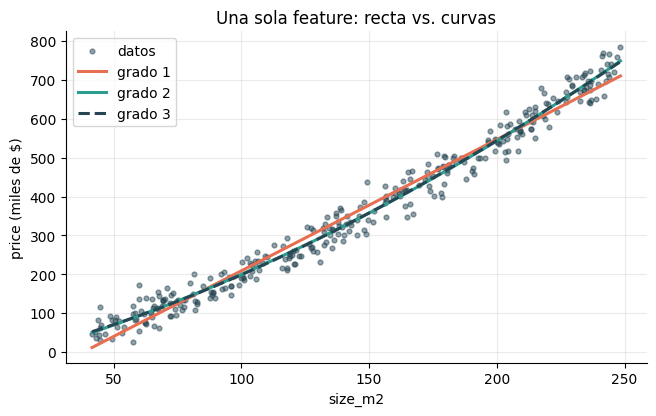

In [ ]:
require("Ejercicio 6: polynomial_features")
size_col = X_train[:, [0]]                      # (m, 1): just the size
grid = np.linspace(size_col.min(), size_col.max(), 200).reshape(-1, 1)

plt.figure(figsize=(7.5, 4.3))
plt.scatter(size_col, y_train, s=12, alpha=0.5, color="#264653", label="datos")
for degree, color, style in zip((1, 2, 3), ("#e76f51", "#2a9d8f", "#264653"), ("-", "-", "--")):
    w_d, b_d = closed_form_solution(polynomial_features(size_col, degree), y_train)
    plt.plot(grid, polynomial_features(grid, degree) @ w_d + b_d, color=color, ls=style, lw=2.2, label=f"grado {degree}")
plt.xlabel("size_m2")
plt.ylabel("price (miles de $)")
plt.title("Una sola feature: recta vs. curvas")
plt.legend()
plt.show()

👀 La recta se queda corta en los extremos; la parábola sigue mejor la nube de puntos. ¿Y la cúbica? Casi no cambia respecto a la parábola. Verás qué pasa con **las 4 features a la vez** en los experimentos.

---
# 8️⃣ ✍️ Pipeline y experimentos

Llegó la hora de experimentar con **todo lo que construiste**. El flujo es siempre el mismo:

```
X_train, X_val  →  [polynomial features]  →  [normalización con mu/sigma del TRAIN]  →  gradient descent  →  evaluar en validación
```

## Ejercicio 7 — `build_features`

Para no repetir código en cada experimento, junta los pasos en una función que **transforma entrenamiento y validación de la misma manera**.

📐 **Shapes:** entradas `(m_train, n)` y `(m_val, n)` → salidas `(m_train, n·degree)` y `(m_val, n·degree)`

<details>
<summary>💡 Hint 1 (orden)</summary>

Primero las potencias (Ejercicio 6) en **ambos** conjuntos; después, si `normalize` es `True`, la normalización (Ejercicio 5).
</details>

<details>
<summary>💡 Hint 2 (data leakage)</summary>

`mu` y `sigma` se calculan **solo** con la versión de entrenamiento (`zscore_fit` sobre el train) y se **reutilizan** para transformar validación. Nunca llames a `zscore_fit` sobre validación.
</details>

<details>
<summary>💡 Hint 3 (casi la respuesta)</summary>

`X_tr = polynomial_features(X_train, degree)` y lo mismo para `X_va`.
`if normalize:` → `mu, sigma = zscore_fit(X_tr)` y luego `zscore_transform` sobre **ambos**.
</details>

In [ ]:
def build_features(X_train, X_val, degree=1, normalize=True):
    """Feature pipeline: polynomial features -> z-score normalization (fitted on train only).

    Args:
        X_train: (m_train, n), X_val: (m_val, n)
        degree: polynomial degree (1 = original features)
        normalize: whether to apply z-score normalization
    Returns:
        X_tr: (m_train, n * degree), X_va: (m_val, n * degree)
    """
    X_tr = polynomial_features(X_train, degree)
    X_va = polynomial_features(X_val, degree)
    if normalize:
        mu, sigma = zscore_fit(X_tr)  # Ajustar SOLO con entrenamiento.
        X_tr = zscore_transform(X_tr, mu, sigma)
        X_va = zscore_transform(X_va, mu, sigma)
    return X_tr, X_va

In [ ]:
# ✅ Test (no modificar)
require("Ejercicio 5: z-score", "Ejercicio 6: polynomial_features")
X_tr_t, X_va_t = build_features(X_train, X_val, degree=2, normalize=True)

assert X_tr_t is not None and X_va_t is not None, "build_features devolvió None: ¿ya escribiste tu código?"
assert X_tr_t.shape == (X_train.shape[0], 8) and X_va_t.shape == (X_val.shape[0], 8), (
    f"Con degree=2 y 4 features esperaba 8 columnas y obtuve {X_tr_t.shape} y {X_va_t.shape}.")
assert np.allclose(X_tr_t.mean(axis=0), 0, atol=1e-8) and np.allclose(X_tr_t.std(axis=0), 1), "El conjunto de ENTRENAMIENTO normalizado debe tener media 0 y std 1."
assert not np.allclose(X_va_t.mean(axis=0), 0, atol=1e-8), (
    "El conjunto de VALIDACIÓN no debería quedar con media exactamente 0: debes normalizarlo con el mu y sigma del TRAIN (¡no con los suyos!).")

X_tr_raw, X_va_raw = build_features(X_train, X_val, degree=1, normalize=False)
assert np.allclose(X_tr_raw, X_train) and np.allclose(X_va_raw, X_val), "Con degree=1 y normalize=False los datos deben quedar intactos."
mark_passed("Ejercicio 7: build_features")

✅ ¡Ejercicio 7: build_features: correcto!


## 8.1 Reglas del juego (para que la comparación sea justa)

- Todos los experimentos parten de `w = 0`, `b = 0` y corren **`NUM_ITERS = 1000`** iteraciones.
- Se evalúan en el conjunto de **validación** con:
  - **RMSE** $=\sqrt{\frac1m\sum_i(\hat y^{(i)}-y^{(i)})^2}$ → error típico, en **miles de dólares** (menor = mejor);
  - **R²** → fracción de la variabilidad del precio que explica el modelo (más cerca de 1 = mejor).
- Como referencia, cada experimento calcula también el **óptimo exacto** (ecuación normal) para *esas mismas features*, y reporta el **"exceso vs. óptimo"**: cuánto porcentaje más alto es tu costo final de entrenamiento respecto al mejor posible. Si es casi 0 %, gradient descent **convergió**.

Las celdas siguientes son *helpers* (no las modifiques):

- `run_experiment(...)` entrena con **tu** `gradient_descent` y guarda los resultados.
- `plot_experiment(res)` dibuja la curva de costo y las predicciones en validación.
- `scan_alphas(X, y, alphas)` prueba rápidamente varios $\alpha$ y te dice cuáles divergen: ¡úsala para **explorar**!
- `check_experiment(...)` es el test automático de cada experimento.

In [ ]:
NUM_ITERS = 1000
RESULTS = {}


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


def r2_score(y_true, y_pred):
    return 1.0 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)


def run_experiment(name, X_tr, y_tr, X_va, y_va, alpha, num_iters=NUM_ITERS):
    """Train with YOUR gradient_descent and store/print the results."""
    require("Ejercicio 4: gradient_descent", "Ejercicio 5: z-score", "Ejercicio 6: polynomial_features", "Ejercicio 7: build_features")
    assert alpha is not None, "Define alpha antes de correr el experimento (busca el # tu código aquí)."
    assert X_tr is not None and X_va is not None, "Construye X_tr y X_va con build_features (busca el # tu código aquí)."
    n = X_tr.shape[1]
    with np.errstate(over="ignore", invalid="ignore"):      # diverging runs overflow: that is expected
        w, b, J_hist, _ = gradient_descent(X_tr, y_tr, np.zeros(n), 0.0, alpha, num_iters)
        J_hist = np.array(J_hist, dtype=float)
        diverged = bool((not np.isfinite(J_hist[-1])) or J_hist[-1] > J_hist[0])
        w_opt, b_opt = closed_form_solution(X_tr, y_tr)
        J_opt = compute_cost(X_tr, y_tr, w_opt, b_opt)
        excess = 100 * (J_hist[-1] - J_opt) / J_opt if np.isfinite(J_hist[-1]) else np.inf
        y_pred_val = predict(X_va, w, b)
        res = dict(name=name, alpha=alpha, num_iters=num_iters, J_hist=J_hist, J_opt=J_opt, diverged=diverged,
                   excess_pct=excess, y_val=y_va, y_pred_val=y_pred_val,
                   train_rmse=rmse(y_tr, predict(X_tr, w, b)), val_rmse=rmse(y_va, y_pred_val),
                   val_r2=r2_score(y_va, y_pred_val))
    RESULTS[name] = res
    if diverged:
        print(f"{name}\n   α = {alpha:g}  ->  💥 DIVERGIÓ (el costo pasó de {J_hist[0]:.4g} a {J_hist[-1]:.4g})")
    else:
        print(f"{name}\n   α = {alpha:g} | costo final = {J_hist[-1]:.4g} | exceso vs. óptimo = {excess:.3g} %"
              f"\n   RMSE train = {res['train_rmse']:.2f} | RMSE val = {res['val_rmse']:.2f} (miles de $) | R² val = {res['val_r2']:.4f}")
    return res


def plot_experiment(res):
    """Cost curve (log scale) and real-vs-predicted prices on the validation set."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8))
    J_plot = np.clip(np.where(np.isfinite(res["J_hist"]), res["J_hist"], np.nan), None, 1e12)  # avoid inf/overflow in the plot
    ax1.plot(J_plot, color="#e76f51")
    ax1.axhline(res["J_opt"], color="black", ls="--", lw=1, label="óptimo exacto")
    ax1.set_yscale("log")
    ax1.set_xlabel("iteración")
    ax1.set_ylabel("costo J (escala log)")
    ax1.set_title(res["name"] + (" — divergió (curva recortada en 10¹²)" if res["diverged"] else ""), fontsize=10.5)
    ax1.legend()
    if res["diverged"]:
        ax2.text(0.5, 0.5, "sin predicciones válidas", ha="center", va="center", fontsize=12)
        ax2.axis("off")
    else:
        lim = [min(res["y_val"].min(), res["y_pred_val"].min()), max(res["y_val"].max(), res["y_pred_val"].max())]
        ax2.scatter(res["y_val"], res["y_pred_val"], s=14, alpha=0.7, color="#264653")
        ax2.plot(lim, lim, "k--", lw=1)
        ax2.set_xlabel("precio real (validación)")
        ax2.set_ylabel("precio predicho")
        ax2.set_title(f"RMSE val = {res['val_rmse']:.1f}   R² = {res['val_r2']:.3f}", fontsize=10.5)
    plt.tight_layout()
    plt.show()


def scan_alphas(X, y, alphas, num_iters=NUM_ITERS):
    """Exploration helper: train with each alpha and show the initial and final cost."""
    n = X.shape[1]
    print(f"{'alpha':>10} | {'costo inicial':>14} | {'costo final':>14} | estado")
    for alpha in alphas:
        with np.errstate(over="ignore", invalid="ignore"):
            _, _, J, _ = gradient_descent(X, y, np.zeros(n), 0.0, alpha, num_iters)
        state = "💥 diverge" if (not np.isfinite(J[-1]) or J[-1] > J[0]) else "baja"
        print(f"{alpha:>10g} | {J[0]:>14.4g} | {J[-1]:>14.4g} | {state}")


def check_experiment(res, kind):
    """Automatic checks for each experiment (the TYPE of behaviour we expect)."""
    names = {"raw": "Experimento 1: sin normalizar", "too_small": "Experimento 2: α muy pequeño",
             "ideal": "Experimento 3: α ideal", "too_large": "Experimento 4: α muy grande",
             "poly2": "Experimento 5: polinomial grado 2", "poly3": "Experimento 6: polinomial grado 3"}
    J = res["J_hist"]
    finite = bool(np.all(np.isfinite(J)))
    decreasing = finite and bool(np.all(np.diff(J) <= 1e-9 * np.abs(J[:-1])))
    excess = res["excess_pct"]
    if kind == "raw":
        assert finite and not res["diverged"], ("💥 El costo explotó. Sin normalizar necesitas un α MUCHÍSIMO más pequeño: "
                                                "baja α por factores de 10 (usa scan_alphas) hasta que el costo deje de divergir.")
        assert decreasing, "El costo debe bajar en cada iteración: reduce un poco más α."
        assert excess > 10, (f"Tu modelo quedó a solo {excess:.1f} % del óptimo. Con features SIN normalizar no debería converger tan bien en 1000 iteraciones: "
                             "verifica que no estés normalizando (normalize=False).")
    elif kind == "too_small":
        assert decreasing, "Con un α pequeño el costo igual debe bajar en cada iteración; revisa que no sea negativo ni demasiado grande."
        assert excess > 10, (f"Con tu α el modelo ya quedó a solo {excess:.1f} % del óptimo: todavía no es 'muy pequeño'. "
                             "Prueba un α 10 veces menor.")
    elif kind == "ideal":
        assert not res["diverged"], "Tu α hace que el costo diverja: elige uno más pequeño."
        assert decreasing, "Con un α ideal el costo debe bajar en TODAS las iteraciones."
        assert excess < 5, (f"Tu modelo quedó a {excess:.1f} % del óptimo tras {res['num_iters']} iteraciones: todavía no es 'ideal'. "
                            "Prueba un α más grande (pero sin que diverja) con scan_alphas.")
    elif kind == "too_large":
        assert res["diverged"], ("Tu α no hace divergir el algoritmo. Elige uno MAYOR que el α máximo estable "
                                 "(pista: max_stable_alpha(X_tr)).")
    elif kind in ("poly2", "poly3"):
        assert not res["diverged"], ("El costo diverge: con más features el α máximo estable BAJA. "
                                     "Reduce α (o consulta max_stable_alpha(X_tr)).")
        assert decreasing, "El costo debe bajar en todas las iteraciones."
        assert excess < 5, f"Tu modelo quedó a {excess:.1f} % del óptimo: sube un poco α (sin que diverja)."
        if kind == "poly2":
            ref = RESULTS.get("Exp 3: α ideal")
            if ref is not None:
                assert res["val_rmse"] < ref["val_rmse"], (
                    "Con features polinomiales el RMSE de validación debería ser MENOR que el del Exp 3. "
                    "Revisa que uses degree=2 y que normalices DESPUÉS de crear las potencias.")
    mark_passed(names[kind])

## Experimento 1 — Sin normalizar

🎯 **Pregunta:** ¿qué pasa si entrenamos con las features **tal cual** (en sus escalas originales)?

**Qué hacer:**
1. Construye `X_tr`, `X_va` **sin** polinomios (`degree=1`) y **sin** normalizar (`normalize=False`).
2. Encuentra el **mayor** $\alpha$ con el que el costo **no** diverge. Pista de exploración: `scan_alphas(X_tr, y_train, [1e-3, 1e-4, 1e-5, 1e-6])`.

<details>
<summary>💡 Hint 1</summary>

Con estas escalas, un $\alpha$ "normal" como 0.01 hace explotar el costo de inmediato. Prueba valores de orden $10^{-5}$ y $10^{-6}$.
</details>

<details>
<summary>💡 Hint 2</summary>

También puedes consultar `max_stable_alpha(X_tr)` (sección 6.3) y quedarte **un poco por debajo** de ese valor.
</details>

Límite de estabilidad de α: 7.831655e-05
     alpha |  costo inicial |    costo final | estado
     0.001 |       8.63e+04 |            nan | 💥 diverge
    0.0001 |       8.63e+04 |            inf | 💥 diverge
     1e-05 |       8.63e+04 |          613.5 | baja
     1e-06 |       8.63e+04 |           1456 | baja
Exp 1: sin normalizar
   α = 7.75334e-05 | costo final = 506.6 | exceso vs. óptimo = 81.9 %
   RMSE train = 31.83 | RMSE val = 31.07 (miles de $) | R² val = 0.9721


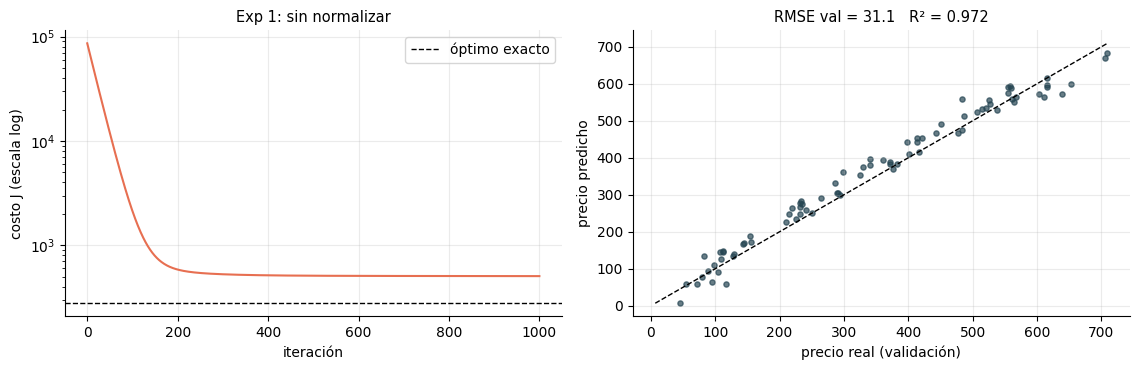

In [ ]:
X_tr, X_va = build_features(X_train, X_val, degree=1, normalize=False)
alpha_max = max_stable_alpha(X_tr)
print(f"Límite de estabilidad de α: {alpha_max:.8g}")

scan_alphas(X_tr, y_train, [1e-3, 1e-4, 1e-5, 1e-6])
# El límite teórico es 2/lambda_max: usamos el 99 % para quedar por debajo.
alpha = 0.99 * alpha_max

res1 = run_experiment("Exp 1: sin normalizar", X_tr, y_train, X_va, y_val, alpha)
plot_experiment(res1)

In [ ]:
# ✅ Test (no modificar)
check_experiment(res1, "raw")

✅ ¡Experimento 1: sin normalizar: correcto!


## Experimento 2 — Learning rate **muy pequeño**

🎯 **Pregunta:** ¿qué pasa si $\alpha$ es demasiado pequeño?

**Qué hacer:** usa features **normalizadas** (`degree=1`, `normalize=True`) y elige un $\alpha$ tan pequeño que, tras 1000 iteraciones, el modelo siga **lejos del óptimo** (aunque el costo sí baje en cada paso).

<details>
<summary>💡 Hint 1</summary>

Con features normalizadas, los valores razonables de $\alpha$ están entre 0.01 y 1. Para "muy pequeño" baja varios órdenes de magnitud: $10^{-3}$, $10^{-4}$...
</details>

<details>
<summary>💡 Hint 2</summary>

Recuerda la figura 3.6 (izquierda): pasos diminutos → avance lentísimo. Verifica con `scan_alphas`.
</details>

Límite de estabilidad de α: 1.0817385
Exp 2: α muy pequeño
   α = 0.0001 | costo final = 6.839e+04 | exceso vs. óptimo = 2.45e+04 %
   RMSE train = 369.83 | RMSE val = 349.64 (miles de $) | R² val = -2.5388


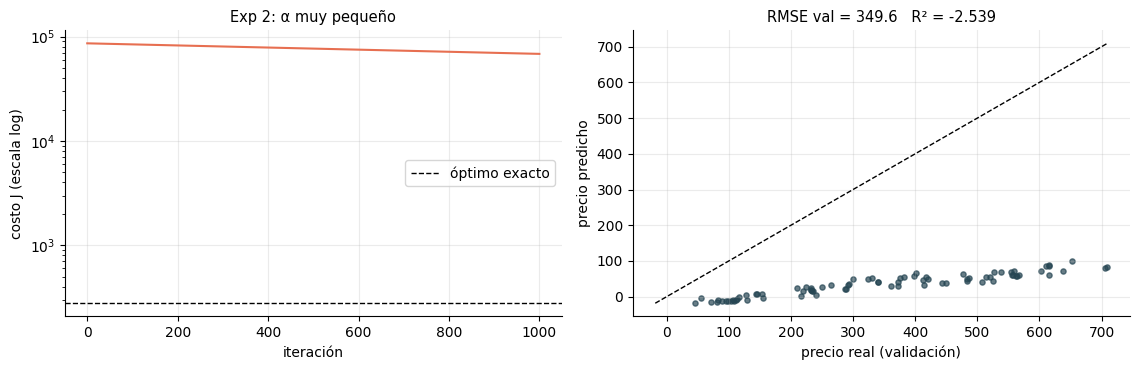

In [ ]:
X_tr, X_va = build_features(X_train, X_val, degree=1, normalize=True)
alpha_max = max_stable_alpha(X_tr)
print(f"Límite de estabilidad de α: {alpha_max:.8g}")

# Pasos diminutos: baja el costo, pero 1000 iteraciones no bastan.
alpha = 1e-4

res2 = run_experiment("Exp 2: α muy pequeño", X_tr, y_train, X_va, y_val, alpha)
plot_experiment(res2)

In [ ]:
# ✅ Test (no modificar)
check_experiment(res2, "too_small")

✅ ¡Experimento 2: α muy pequeño: correcto!


## Experimento 3 — Learning rate **ideal**

🎯 **Pregunta:** ¿qué tan bien funciona el modelo lineal cuando gradient descent está bien configurado?

**Qué hacer:** mismas features normalizadas, pero busca un $\alpha$ que **converja casi hasta el óptimo en 1000 iteraciones sin diverger**.

<details>
<summary>💡 Hint 1</summary>

Explora en escala logarítmica: `scan_alphas(X_tr, y_train, [0.001, 0.01, 0.1, 0.5, 1.0])`. Quédate con uno donde el costo final sea el más bajo **sin** marcar 💥.
</details>

<details>
<summary>💡 Hint 2</summary>

Con features normalizadas el α ideal suele estar entre 0.05 y 0.5. Valores muy cercanos al máximo estable (`max_stable_alpha`) son riesgosos.
</details>

Límite de estabilidad de α: 1.0817385
     alpha |  costo inicial |    costo final | estado
     0.001 |       8.63e+04 |      1.049e+04 | baja
      0.01 |       8.63e+04 |          333.7 | baja
       0.1 |       8.63e+04 |          278.5 | baja
       0.5 |       8.63e+04 |          278.5 | baja
         1 |       8.63e+04 |          278.5 | baja
Exp 3: α ideal
   α = 0.1 | costo final = 278.5 | exceso vs. óptimo = 9.86e-12 %
   RMSE train = 23.60 | RMSE val = 25.12 (miles de $) | R² val = 0.9817


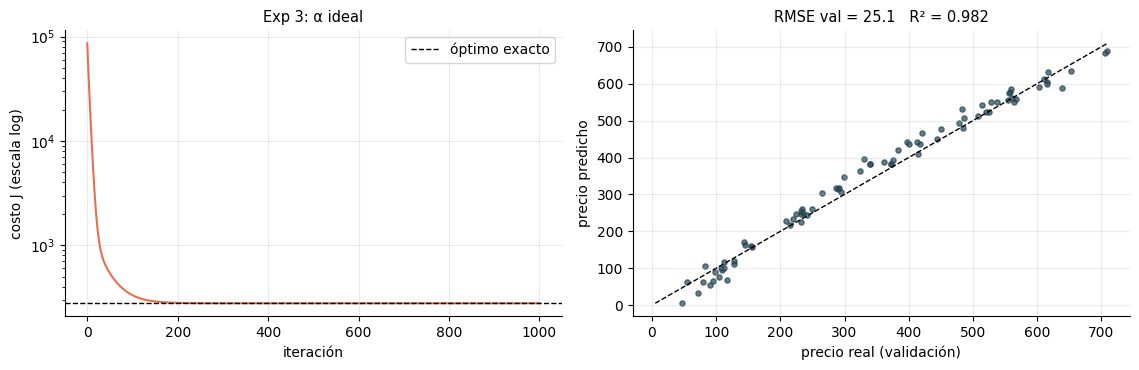

In [ ]:
X_tr, X_va = build_features(X_train, X_val, degree=1, normalize=True)
alpha_max = max_stable_alpha(X_tr)
print(f"Límite de estabilidad de α: {alpha_max:.8g}")

scan_alphas(X_tr, y_train, [0.001, 0.01, 0.1, 0.5, 1.0])
# Elegimos 0.1: converge y queda holgadamente por debajo del límite.
alpha = 0.1

res3 = run_experiment("Exp 3: α ideal", X_tr, y_train, X_va, y_val, alpha)
plot_experiment(res3)

In [ ]:
# ✅ Test (no modificar)
check_experiment(res3, "ideal")

✅ ¡Experimento 3: α ideal: correcto!


## Experimento 4 — Learning rate **muy grande**

🎯 **Pregunta:** ¿qué pasa si $\alpha$ se pasa de la raya?

**Qué hacer:** mismas features normalizadas; elige un $\alpha$ **mayor** que el máximo estable para que el algoritmo **diverja**.

<details>
<summary>💡 Hint 1</summary>

Calcula `max_stable_alpha(X_tr)` y elige algo claramente mayor (por ejemplo, el doble).
</details>

<details>
<summary>💡 Hint 2</summary>

Es normal que veas el costo crecer hasta valores astronómicos o `inf`/`nan`: eso **es** divergir (figura 3.6, derecha).
</details>

Límite de estabilidad de α: 1.0817385
Exp 4: α muy grande
   α = 2.16348  ->  💥 DIVERGIÓ (el costo pasó de 8.63e+04 a nan)


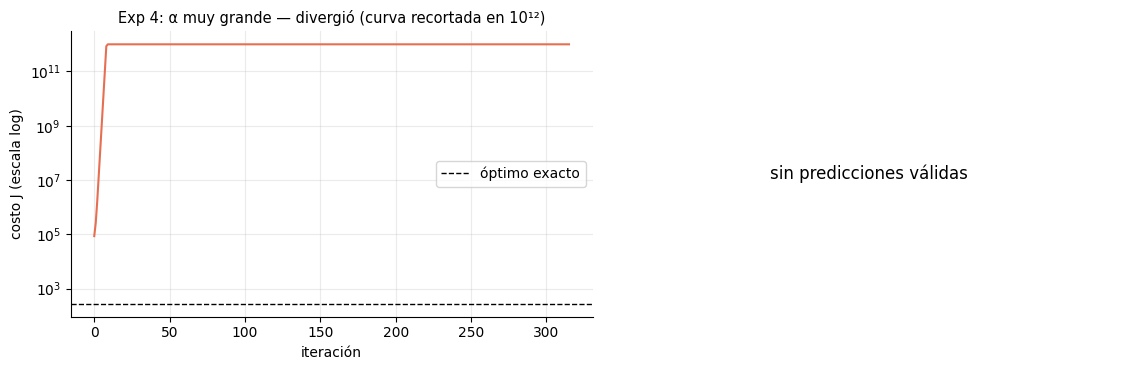

In [ ]:
X_tr, X_va = build_features(X_train, X_val, degree=1, normalize=True)
alpha_max = max_stable_alpha(X_tr)
print(f"Límite de estabilidad de α: {alpha_max:.8g}")

# Superar el límite de estabilidad provoca la divergencia solicitada.
alpha = 2.0 * alpha_max

res4 = run_experiment("Exp 4: α muy grande", X_tr, y_train, X_va, y_val, alpha)
plot_experiment(res4)

In [ ]:
# ✅ Test (no modificar)
check_experiment(res4, "too_large")

✅ ¡Experimento 4: α muy grande: correcto!


## Experimento 5 — Polynomial features de **grado 2** (+ normalización)

🎯 **Pregunta:** ¿mejoran las predicciones si dejamos que el modelo dibuje curvas?

**Qué hacer:** `degree=2`, `normalize=True` y un $\alpha$ que converja. Empieza con el α ideal del Experimento 3.

<details>
<summary>💡 Hint 1</summary>

Con 8 features en lugar de 4, el $\alpha$ máximo estable es **menor**. Si el costo explota con el α del Exp 3, redúcelo.
</details>

Límite de estabilidad de α: 0.54985628
Exp 5: polinomial grado 2
   α = 0.494871 | costo final = 108 | exceso vs. óptimo = 0.000289 %
   RMSE train = 14.70 | RMSE val = 15.96 (miles de $) | R² val = 0.9926


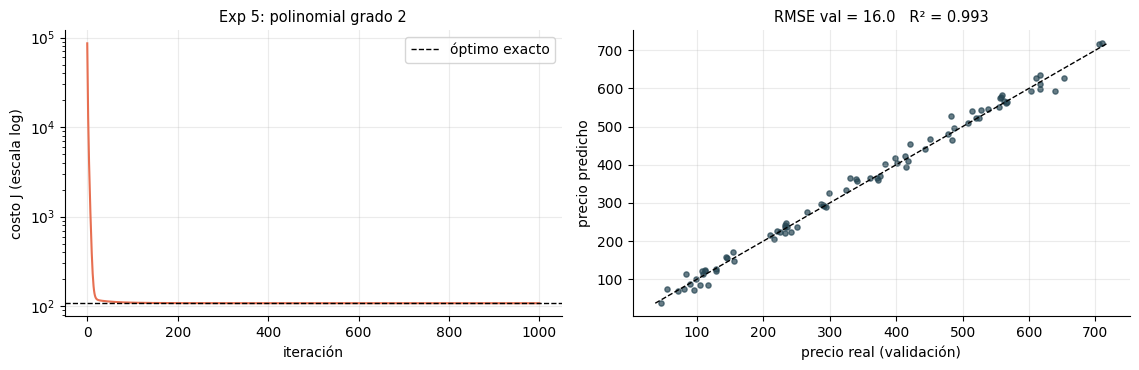

In [ ]:
X_tr, X_va = build_features(X_train, X_val, degree=2, normalize=True)
alpha_max = max_stable_alpha(X_tr)
print(f"Límite de estabilidad de α: {alpha_max:.8g}")

# Más columnas correlacionadas: recalculamos el límite y dejamos margen.
alpha = 0.9 * alpha_max

res5 = run_experiment("Exp 5: polinomial grado 2", X_tr, y_train, X_va, y_val, alpha)
plot_experiment(res5)

In [ ]:
# ✅ Test (no modificar)
check_experiment(res5, "poly2")

✅ ¡Experimento 5: polinomial grado 2: correcto!


## Experimento 6 — Polynomial features de **grado 3** (+ normalización)

🎯 **Pregunta:** si grado 2 ayuda, ¿grado 3 ayuda todavía más?

**Qué hacer:** `degree=3`, `normalize=True` y un $\alpha$ que converja (con 12 features el α máximo estable baja otra vez).

<details>
<summary>💡 Hint 1</summary>

Consulta `max_stable_alpha(X_tr)` para saber hasta dónde puedes subir sin que diverja, y escoge un valor holgadamente por debajo.
</details>

Límite de estabilidad de α: 0.37441861
Exp 6: polinomial grado 3
   α = 0.336977 | costo final = 107.7 | exceso vs. óptimo = 1.6 %
   RMSE train = 14.68 | RMSE val = 15.90 (miles de $) | R² val = 0.9927


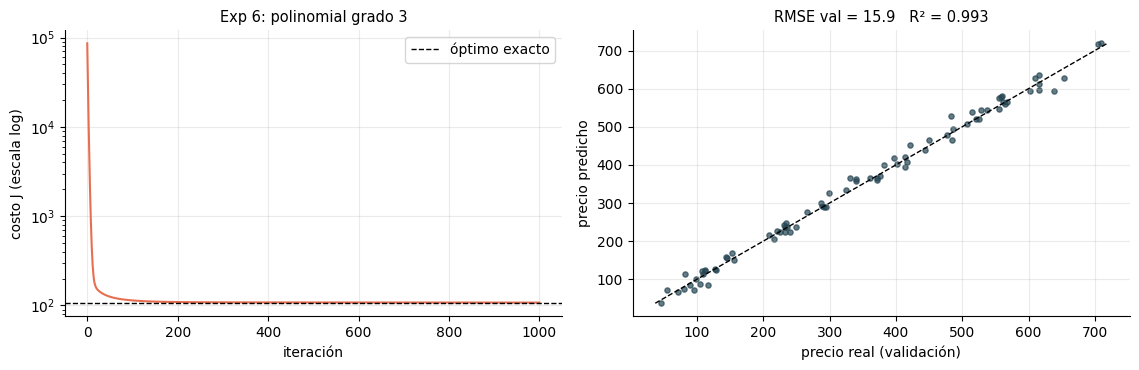

In [ ]:
X_tr, X_va = build_features(X_train, X_val, degree=3, normalize=True)
alpha_max = max_stable_alpha(X_tr)
print(f"Límite de estabilidad de α: {alpha_max:.8g}")

# Se normalizan las potencias con estadísticas del entrenamiento.
alpha = 0.9 * alpha_max

res6 = run_experiment("Exp 6: polinomial grado 3", X_tr, y_train, X_va, y_val, alpha)
plot_experiment(res6)

In [ ]:
# ✅ Test (no modificar)
check_experiment(res6, "poly3")

✅ ¡Experimento 6: polinomial grado 3: correcto!


---
# 9️⃣ 📊 Comparación y conclusión

## 9.1 Todos los experimentos juntos

La siguiente celda (helper) arma la **tabla comparativa** y dos gráficas: las curvas de costo de todos los experimentos y el RMSE de validación de cada uno.

In [ ]:
def compare_experiments(results):
    """Summary table + plots for all finished experiments."""
    rows = sorted(results.values(), key=lambda r: (r["diverged"], r["val_rmse"] if not r["diverged"] else 0))
    print(f"{'Experimento':<28} {'α':>9} {'exceso vs. óptimo':>18} {'RMSE train':>11} {'RMSE val':>9} {'R² val':>8}")
    print("-" * 90)
    for r in rows:
        if r["diverged"]:
            print(f"{r['name']:<28} {r['alpha']:>9g} {'💥 divergió':>18} {'—':>11} {'—':>9} {'—':>8}")
        else:
            print(f"{r['name']:<28} {r['alpha']:>9g} {r['excess_pct']:>17.3g}% {r['train_rmse']:>11.2f} {r['val_rmse']:>9.2f} {r['val_r2']:>8.4f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
    for r in results.values():
        J = np.where(np.isfinite(r["J_hist"]), r["J_hist"], np.nan)
        ax1.plot(np.clip(J, None, 1e12), label=r["name"] + (" (diverge)" if r["diverged"] else ""))
    ax1.set_yscale("log")
    ax1.set_xlabel("iteración")
    ax1.set_ylabel("costo J (escala log)")
    ax1.set_title("Curvas de costo (entrenamiento)")
    ax1.legend(fontsize=8)

    ok = [r for r in results.values() if not r["diverged"]]
    ok.sort(key=lambda r: r["val_rmse"])
    bars = ax2.barh([r["name"] for r in ok][::-1], [r["val_rmse"] for r in ok][::-1], color="#2a9d8f")
    for bar in bars:
        ax2.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {bar.get_width():.1f}", va="center", fontsize=9)
    ax2.set_xlabel("RMSE de validación (miles de $) — menor es mejor")
    ax2.set_title("Error en validación (solo experimentos que no divergieron)")
    plt.tight_layout()
    plt.show()

    best = ok[0]
    ties = [r["name"] for r in ok[1:] if r["val_rmse"] <= best["val_rmse"] * 1.01]
    print(f"\n🏆 Menor RMSE de validación: {best['name']} ({best['val_rmse']:.2f})")
    if ties:
        print(f"🤝 Empatados (a menos de 1 % de diferencia): {', '.join(ties)}")

Experimento                          α  exceso vs. óptimo  RMSE train  RMSE val   R² val
------------------------------------------------------------------------------------------
Exp 6: polinomial grado 3     0.336977               1.6%       14.68     15.90   0.9927
Exp 5: polinomial grado 2     0.494871          0.000289%       14.70     15.96   0.9926
Exp 3: α ideal                     0.1          9.86e-12%       23.60     25.12   0.9817
Exp 1: sin normalizar        7.75334e-05              81.9%       31.83     31.07   0.9721
Exp 2: α muy pequeño            0.0001          2.45e+04%      369.83    349.64  -2.5388
Exp 4: α muy grande            2.16348         💥 divergió           —         —        —


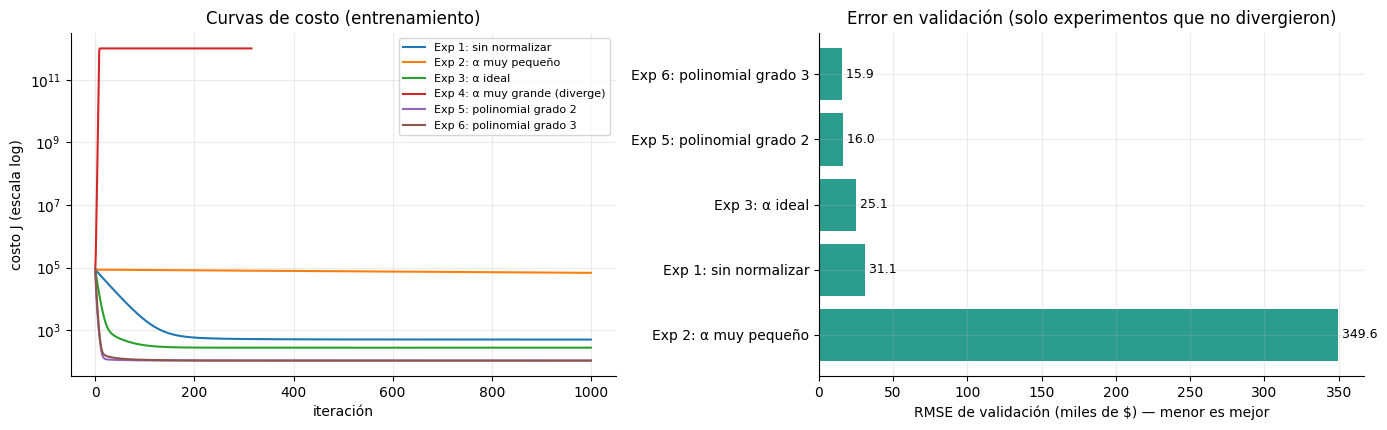


🏆 Menor RMSE de validación: Exp 6: polinomial grado 3 (15.90)
🤝 Empatados (a menos de 1 % de diferencia): Exp 5: polinomial grado 2


In [ ]:
assert len(RESULTS) == 6, f"Faltan experimentos: tienes {len(RESULTS)} de 6. Ejecuta todas las celdas de la sección 8."
compare_experiments(RESULTS)

## 9.2 Mi conclusión

### Tabla resumen de los resultados ejecutados

Todos los experimentos usaron la misma partición de 320 casas para entrenamiento y 80 para validación, parámetros iniciales en cero y **1000 iteraciones**. Cada exceso se calcula respecto al óptimo de las features de ese experimento. Los RMSE se expresan en miles de dólares.

| Experimento | α | Exceso vs. óptimo | RMSE train | RMSE val (miles de $) | R² val |
|---|---:|---:|---:|---:|---:|
| Exp 1: sin normalizar | 7.7533384e-05 | 81.898128 % | 31.8310 | 31.0703 | 0.972055 |
| Exp 2: α muy pequeño | 0.0001 | 24454.130232 % | 369.8263 | 349.6383 | -2.538807 |
| Exp 3: α ideal | 0.1 | ≈ 0 % | 23.6013 | 25.1207 | 0.981732 |
| Exp 4: α muy grande | 2.1634769 | Divergió | — | — | — |
| Exp 5: polinomial grado 2 | 0.49487066 | 0.000289 % | 14.6964 | 15.9562 | 0.992630 |
| Exp 6: polinomial grado 3 | 0.33697675 | 1.602417 % | 14.6761 | 15.8985 | 0.992683 |

### 1. Learning rate

Con **α = 0.0001** (Exp 2), el costo bajó de **86303.14** a **68385.75**, pero quedó **24454.13 %** por encima del óptimo. El RMSE de validación fue **349.6383** y R² fue **-2.538807**. Los pasos son tan pequeños que 1000 actualizaciones no bastan para acercarse al mínimo; el R² negativo indica que estas predicciones son peores que usar la media del conjunto de validación como referencia.

En cambio, con **α = 2.16347693** (Exp 4), el algoritmo divergió: el costo creció hasta producir valores no finitos. Este α duplica el límite teórico del modelo normalizado, **1.08173847**. En la parábola del costo, pasos excesivos hacen que las actualizaciones salten de un lado a otro y se alejen del mínimo. Para esta función cuadrática, la convergencia requiere **0 < α < 2/λ_max** de la matriz de curvatura que incluye el sesgo.

Con **α = 0.1** (Exp 3), el costo llegó a **278.510180**, prácticamente igual al óptimo **278.510180**, sin divergir.

### 2. Normalización

Sin normalizar (Exp 1), tuve que usar **α = 7.7533384e-05**, el 99 % del límite teórico, para mantener la estabilidad. Aun así, después de 1000 iteraciones el costo fue **506.6048**, con **81.8981 %** de exceso, y el RMSE de validación fue **31.0703**. La curva baja, pero avanza lentamente en las direcciones menos empinadas.

Al normalizar (Exp 3), pude usar **α = 0.1** y el RMSE de validación bajó a **25.1207**. Z-score pone las columnas en escalas comparables, reduce la diferencia de curvatura entre direcciones y facilita la optimización. Los dos modelos lineales tienen el mismo costo óptimo (**278.510180**): la mejora observada proviene de acercarse mejor al mínimo con el mismo presupuesto de iteraciones.

Calculé la media y la desviación estándar **solo con entrenamiento** y las reutilicé en validación, evitando filtrar información de validación hacia el ajuste.

### 3. Polynomial features

El grado 2 (Exp 5) redujo el RMSE de validación de **25.1207** a **15.9562**, una mejora de **36.48 %**, y alcanzó **R² = 0.992630**. Las columnas cuadráticas permiten representar las curvaturas presentes en los datos sintéticos. La expansión usada es **[X | X²]**, sin interacciones entre columnas; primero calculé las potencias y después las normalicé.

Con grado 3 (Exp 6), el RMSE bajó ligeramente a **15.8985** y R² subió a **0.992683**. La mejora frente al grado 2 fue de solo **0.36 %**. Ambos cumplieron el criterio del ejercicio de quedar a menos del 5 % de su costo óptimo: grado 2 tuvo **0.000289 %** de exceso y grado 3 tuvo **1.602417 %**. Por eso, tampoco debo confundir el resultado de 1000 iteraciones con la solución óptima exacta del modelo cúbico.

Al aumentar el grado, el límite de estabilidad de α disminuyó: **1.081738** con 4 features, **0.549856** con 8 y **0.374419** con 12. Para los grados 2 y 3 usé el 90 % de sus respectivos límites: **0.49487066** y **0.33697675**. Agregar potencias correlacionadas exige volver a ajustar el learning rate.

### 4. Veredicto

**El experimento que produjo el menor RMSE de validación fue el Exp 6, polinomial de grado 3, porque alcanzó 15.8985 miles de dólares.** Sin embargo, preferiría el **Exp 5, grado 2**, porque su diferencia es de apenas **0.36 %**, menor al 1 % indicado como empate práctico. Usa 8 features en lugar de 12 y obtiene prácticamente el mismo desempeño con menor complejidad. Esta partición no demuestra una mejora relevante de generalización al añadir el grado cúbico.

### 5. Recomendación

Para estos datos elegiría **features de grado 2 sin interacciones, normalización z-score posterior a las potencias, α = 0.49487066 y 1000 iteraciones**. Guardaría los pesos, el sesgo y las estadísticas de entrenamiento para transformar las nuevas casas exactamente igual. Antes de poner un modelo real en producción, lo evaluaría en datos reales y en un conjunto de prueba independiente: estos resultados corresponden a datos sintéticos y la validación ya se utilizó para comparar configuraciones.

La vectorización permitió escribir las predicciones, el costo y los gradientes con productos de NumPy, sin recorrer ejemplos ni features con ciclos de Python. El ciclo principal conserva únicamente las iteraciones del entrenamiento y actualiza pesos y sesgo con gradientes calculados sobre los mismos parámetros actuales.


## 9.3 Resumen de ejercicios y verificación de reglas

In [ ]:
show_progress()

forbidden = {"torch", "tensorflow", "keras", "jax", "sklearn"}
loaded = sorted(forbidden & set(sys.modules))
if loaded:
    print(f"\n⚠️  Detecté librerías no permitidas cargadas en esta sesión: {loaded}. Reinicia el kernel y no las importes.")
else:
    print("\n✅ Regla cumplida: solo NumPy para el algoritmo.")

✅ Mini-ejercicio 1.1: producto punto
✅ Mini-ejercicio 1.2: matriz × vector
✅ Mini-ejercicio 1.3: matriz × matriz
✅ Ejercicio 1: predict
✅ Ejercicio 2: compute_cost
✅ Ejercicio 3: compute_gradient
✅ Ejercicio 4: gradient_descent
✅ Ejercicio 5: z-score
✅ Ejercicio 6: polynomial_features
✅ Ejercicio 7: build_features
✅ Experimento 1: sin normalizar
✅ Experimento 2: α muy pequeño
✅ Experimento 3: α ideal
✅ Experimento 4: α muy grande
✅ Experimento 5: polinomial grado 2
✅ Experimento 6: polinomial grado 3
Progreso: 16/16

✅ Regla cumplida: solo NumPy para el algoritmo.


---
## 🎉 ¡Felicidades!

Implementaste gradient descent para regresión lineal multivariable **desde cero y vectorizado**. Lo que viste aquí es la base de cómo se entrenan las redes neuronales: los mismos productos matriz × vector, el mismo gradiente, la misma regla de actualización (solo que con más capas y la derivada calculada por *backpropagation*).

### 🚀 Retos opcionales
1. **Interacciones:** además de $x^2$, agrega productos entre features (p. ej. `size_m2 * bedrooms`). ¿Mejora el RMSE?
2. **Grado alto:** prueba `degree=6`. ¿Qué pasa con el α máximo estable y con la convergencia?
3. **Criterio de paro:** modifica `gradient_descent` para detenerse cuando el costo baje menos de $10^{-8}$ entre iteraciones.
4. **Mini-batch / estocástico:** actualiza los parámetros usando solo una parte de los ejemplos en cada paso.
5. **Desnormalizar los pesos:** ¿cómo expresarías el modelo final en las unidades originales (m², cuartos, años, km)?

### 📦 Para entregar
- Este notebook **ejecutado de principio a fin** (*Kernel → Restart & Run All*) y con **todos los ✅**.
- La **conclusión de la sección 9.2** escrita por ti.